# USD/EUR Forecasting - ARIMA

Dataset: `CSV/USD_EUR_Historical.csv`; target: `Price`; units: **EUR per USD**. Quote direction follows the source filename. Source fixing time/timezone are unknown.

**Flow:** Step 1 preparation -> Step 2 descriptive EDA -> Step 3 raw chronological 80/20 split -> Step 4 Train stationarity -> Step 5 AIC Top 3 and auto_arima cross-check -> Step 6 Train diagnostics, robust reporting and final model -> Step 7 historical/future forecasts -> Step 8 RMSE/MAPE and plots -> Step 9 execution-generated summary.

The step sequence follows `S&P_TEST/ARIMA_SnP.ipynb`, which shares the BTC Step 1-9 workflow. Horizons [1,3,5,7,14,21,30] count successive source observations. Source dates are retained without interpolation; future dates are weekday-pattern projections, not confirmed FX holiday sessions. No validation; fitted Train parameters remain fixed throughout Test and future filtering.

This user-requested methodology revision follows prior Test inspection; the existing Test period is not a new untouched holdout. Run all cells in Python 3.12 (vs_nine TensorFlow). Outputs: `OUTPUT/ARIMA_USD/{tables,figures,summaries,models}`.


## Configuration and actual kernel versions

Single configuration cell, imports, versions and output helpers; optimizer fitting uses the same `ARIMA.fit()` defaults as the S&P reference.

In [1]:
from pathlib import Path
import os, sys, json, random, hashlib, warnings, time
os.environ.setdefault('TF_ENABLE_ONEDNN_OPTS', '0')
os.environ.setdefault('TF_CPP_MIN_LOG_LEVEL', '2')
from importlib.metadata import version
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.stats as stats
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from statsmodels.stats.stattools import jarque_bera
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from IPython.display import display, Markdown, HTML

from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import adfuller, kpss
import pmdarima as pm

ASSET = 'USD'
ASSET_NAME = 'USD/EUR'
MODEL = 'ARIMA'
UNIT = 'EUR per USD'
ASSET_NOTE = 'Quote direction follows USD/EUR in the supplied filename: EUR for one USD. The CSV does not specify fixing time or timezone.'
PROJECT_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'CSV' / 'USD_EUR_Historical.csv').is_file()), None)
if PROJECT_ROOT is None: raise FileNotFoundError('Start Jupyter in PROJECT_2026 or the asset notebook folder.')
DATA_PATH = PROJECT_ROOT / 'CSV' / 'USD_EUR_Historical.csv'
DATE_COL, TARGET_COL, DATE_FORMAT = 'Date', 'Price', '%m/%d/%Y'
TRAIN_RATIO = 0.8
HORIZONS = [1, 3, 5, 7, 14, 21, 30]
DAILY_FORECAST_WINDOWS = [7, 30]
TRANSFORMATION = 'log price; exponential inversion gives a conditional median'
WEEKMASK = 'Mon Tue Wed Thu Fri'
CALENDAR_NOTE = 'Observation-index modeling; source dates retained without filling gaps. Future dates use the declared weekday pattern only; holidays, omitted records and source-session conventions remain unknown.'
CALENDAR_POLICY_USER_ACKNOWLEDGED = False
ALPHA = 0.05
DIAGNOSTIC_LAGS = [10,20,30]
ROLLING_WINDOW = 30
SETTINGS = {'max_p': 5, 'max_q': 5, 'max_d': 2, 'top_k': 3, 'selection': 'lowest AIC among top 3 converged finite-AIC Train candidates passing Ljung-Box at lags 10/20/30 and ARMA roots; stop if none passes'}
PACKAGES = ['numpy', 'pandas', 'matplotlib', 'scipy', 'statsmodels', 'pmdarima']
assert max(DAILY_FORECAST_WINDOWS) <= max(HORIZONS)

assert HORIZONS == sorted(set(HORIZONS)) and min(HORIZONS) >= 1
MAX_H = max(HORIZONS)
OUTPUT_DIR = PROJECT_ROOT / 'OUTPUT' / f'{MODEL}_{ASSET}'
TABLE_DIR, FIGURE_DIR, SUMMARY_DIR, MODEL_DIR = [OUTPUT_DIR / k for k in ['tables','figures','summaries','models']]
for directory in [TABLE_DIR, FIGURE_DIR, SUMMARY_DIR, MODEL_DIR]: directory.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'figure.figsize': (12, 4.5), 'figure.dpi': 100, 'axes.grid': True, 'grid.alpha': .2})
notebook_tables, notebook_figures = {}, []

def save_table(frame, name):
    notebook_tables[name] = frame.copy(deep=True)
    frame.to_csv(TABLE_DIR / name, index=False, encoding='utf-8-sig')
    aliases = {'arima_grid.csv': 'grid_search_aic_bic.csv',
               'arima_top_candidates.csv': 'top3_candidates.csv',
               'arima_parameters.csv': 'parameter_significance.csv',
               'arima_roots.csv': 'model_roots.csv',
               'test_forecasts_all.csv': 'forecasts_long.csv',
               'future_forecasts.csv': 'future_forecast_by_horizon.csv',
               'metrics_by_horizon.csv': 'evaluation_by_horizon.csv'}
    if name in aliases:
        notebook_tables[aliases[name]] = frame.copy(deep=True)
        frame.to_csv(TABLE_DIR / aliases[name], index=False, encoding='utf-8-sig')
def save_figure(fig, name):
    notebook_figures.append(name)
    fig.tight_layout()
    fig.savefig(FIGURE_DIR / name, dpi=150, bbox_inches='tight')
    plt.show()
    plt.close(fig)
def show_table(frame):
    display(HTML('<div style="max-height:340px;overflow:auto;border:1px solid #ddd">' +
                 frame.to_html(index=False, float_format=lambda x: f'{x:,.6f}') + '</div>'))
def write_json(path, obj): path.write_text(json.dumps(obj, indent=2, default=str, ensure_ascii=False), encoding='utf-8')
def markdown_table(frame):
    def cell(x):
        if isinstance(x,(float,np.floating)): return f'{x:.6f}'
        return str(x).replace('|','/').replace('\n',' ')
    return '\n'.join(['| '+' | '.join(map(str,frame.columns))+' |',
        '| '+' | '.join(['---']*len(frame.columns))+' |']+
        ['| '+' | '.join(cell(x) for x in row)+' |' for row in frame.itertuples(index=False,name=None)])
def warning_text(caught): return ' | '.join(f'{w.category.__name__}: {w.message}' for w in caught)
versions = pd.DataFrame([(p, version(p)) for p in PACKAGES], columns=['library','version'])
save_table(versions, 'library_versions.csv')
display(versions)
print('Python:', sys.version, '\nExecutable:', sys.executable, '\nData:', DATA_PATH, '\nOutput:', OUTPUT_DIR)
configuration = dict(asset=ASSET, model=MODEL, data=str(DATA_PATH), target=TARGET_COL, date_column=DATE_COL,
    date_format=DATE_FORMAT, unit=UNIT, asset_note=ASSET_NOTE, train_ratio=TRAIN_RATIO,
    horizons=HORIZONS, daily_forecast_windows=DAILY_FORECAST_WINDOWS, horizon_unit='observations', calendar=CALENDAR_NOTE, weekmask=WEEKMASK,
    transformation=TRANSFORMATION, settings=SETTINGS, rolling_window=ROLLING_WINDOW,
    alpha=ALPHA, diagnostic_lags=DIAGNOSTIC_LAGS, validation=False, evaluation='rolling origins from final Train row; frozen fitted parameters',
    design_source='S&P_TEST/ARIMA_SnP.ipynb Step 1-9 layout and ARIMA workflow; USD-specific source/units/calendar',
    fit_method='statsmodels ARIMA.fit() defaults, matching the S&P reference',
    python_executable=sys.executable, python_version=sys.version)
write_json(SUMMARY_DIR / 'configuration.json', configuration)
process_rows = []
def check(name, condition, note='', statistic=None):
    process_rows.append(dict(check=name, statistic=statistic, p_value=np.nan,
                             status='PASS' if bool(condition) else 'FAIL', interpretation=note))
    save_table(pd.DataFrame(process_rows), 'process_checks.csv')
    assert condition, f'{name}: {note}'
def residual_report(values, label, model_df=0):
    values = np.asarray(values, dtype=float)
    assert np.isfinite(values).all()
    rows = []
    lags = [lag for lag in DIAGNOSTIC_LAGS if model_df < lag < len(values)//2]
    lb = acorr_ljungbox(values, lags=lags, model_df=model_df, return_df=True)
    for lag, row in lb.iterrows():
        rows.append(dict(sample=label, check=f'Ljung-Box lag {lag}', statistic=row.lb_stat,
            p_value=row.lb_pvalue, status='REPORTED', interpretation=('Evidence of serial correlation' if row.lb_pvalue <= ALPHA else 'No rejection of residual independence') + f'; model_df={model_df}; reporting only'))
    t, p = stats.ttest_1samp(values, 0.)
    rows.append(dict(sample=label, check='Residual mean t-test', statistic=t, p_value=p, status='REPORTED',
        interpretation=f'Mean={values.mean():.8g}; descriptive, dependent errors limit the t-test'))
    lm, p, _, _ = het_arch(values, nlags=min(10, len(values)//5), ddof=model_df)
    rows.append(dict(sample=label, check='ARCH LM', statistic=lm, p_value=p, status='REPORTED',
        interpretation='Conditional variance evidence; no retuning'))
    jb, p, skew, kurt = jarque_bera(values)
    rows.append(dict(sample=label, check='Jarque-Bera', statistic=jb, p_value=p, status='REPORTED',
        interpretation=f'Normality diagnostic; skew={skew:.5g}; kurtosis={kurt:.5g}; no retuning'))
    return pd.DataFrame(rows)
# Clear completion status at the start, so a stopped rerun cannot certify old exports.
write_json(SUMMARY_DIR / 'execution_audit.json', dict(completed=False, status='RUNNING', asset=ASSET,
    selection=SETTINGS['selection'], note='Existing exports are not certified until Step 9 completes.'))
(SUMMARY_DIR / 'execution_summary.md').write_text('# Execution in progress\n\nRun all steps to complete this execution.\n', encoding='utf-8')


,library,version
0,numpy,2.5.3
1,pandas,2.3.3
2,matplotlib,3.11.1
3,scipy,1.18.1
4,statsmodels,0.15.0
5,pmdarima,2.1.1


Python: 3.12.14 | packaged by Anaconda, Inc. | (main, Aug 27 2026, 14:37:13) [MSC v.1942 64 bit (AMD64)] 
Executable: C:\Users\User\anaconda3\envs\vs_nine_tf\python.exe 
Data: C:\Users\User\Desktop\PROJECT_2026\CSV\USD_EUR_Historical.csv 
Output: C:\Users\User\Desktop\PROJECT_2026\OUTPUT\ARIMA_USD


67

## Step 1 - Data preparation and source-calendar audit

Parse USD dates/prices, inspect invalid/duplicate rows and gaps, and retain observed dates without filling prices. Only Date and Price are model inputs.

In [2]:
raw = pd.read_csv(DATA_PATH, dtype=str, encoding='utf-8-sig')
assert {DATE_COL,TARGET_COL}.issubset(raw.columns)
dates = pd.to_datetime(raw[DATE_COL], format=DATE_FORMAT, errors='coerce')
price = pd.to_numeric(raw[TARGET_COL].str.replace(',', '', regex=False).str.strip(), errors='coerce')
invalid = dates.isna() | ~np.isfinite(price) | price.le(0)
duplicates = dates.duplicated(keep=False)
save_table(raw.loc[invalid | duplicates], 'invalid_or_duplicate_source_rows.csv')
check('Valid dates, finite strictly positive targets, unique dates', not (invalid | duplicates).any(),
      'Log representation was predetermined; stop rather than impute, drop, or offset invalid targets.')
df = pd.DataFrame({'Date': dates, 'Price': price}).sort_values('Date').set_index('Date')
n = len(df)
prices = df.Price.to_numpy()
log_price = np.log(prices)
returns = np.r_[np.nan, np.diff(log_price)]
source_order = 'descending' if dates.is_monotonic_decreasing else ('ascending' if dates.is_monotonic_increasing else 'mixed')
calendar_offset = pd.offsets.CustomBusinessDay(weekmask=WEEKMASK)
expected_calendar = pd.date_range(df.index[0], df.index[-1], freq=calendar_offset)
missing_dates = expected_calendar.difference(df.index)
unexpected_dates = df.index.difference(expected_calendar)
save_table(pd.DataFrame({'date': missing_dates, 'classification': 'not observed; holiday/omission unknown; no imputation'}), 'calendar_missing_dates.csv')
save_table(pd.DataFrame({'date': unexpected_dates}), 'calendar_unexpected_dates.csv')
gaps = pd.DataFrame({'previous_date': df.index[:-1], 'next_date': df.index[1:],
                     'calendar_days': np.diff(df.index.values).astype('timedelta64[D]').astype(int)})
save_table(gaps, 'observation_gaps.csv')
quality = pd.DataFrame([dict(rows=n, source_order=source_order, invalid_targets=int(invalid.sum()),
    duplicate_dates=int(duplicates.sum()), nonpositive_targets=int(price.le(0).sum()),
    missing_relative_to_weekmask=len(missing_dates), unexpected_weekdays=len(unexpected_dates),
    maximum_calendar_gap=int(gaps.calendar_days.max()), volume_missing=int(raw['Vol.'].isna().sum()) if 'Vol.' in raw else None,
    first_date=df.index[0], last_date=df.index[-1], source_sha256=hashlib.sha256(DATA_PATH.read_bytes()).hexdigest(),
    gap_policy=CALENDAR_NOTE)])
save_table(quality, 'data_quality.csv')
save_table(df.reset_index(), 'prepared_target.csv')
display(quality.T)
show_table(gaps.loc[gaps.calendar_days.gt(3)])
show_table(pd.DataFrame({'unobserved_date': missing_dates}))
print(ASSET_NOTE)
print(CALENDAR_NOTE)
print('Only Date and Price are model inputs; blank auxiliary volume is retained in source and is not imputed.')
calendar_audit = pd.DataFrame([
    dict(check='Dates absent relative to declared weekday pattern', count=len(missing_dates), interpretation='Holiday/omission unknown; disclosed without filling'),
    dict(check='Observed dates outside declared weekday pattern', count=len(unexpected_dates), interpretation='Disclosed source dates are retained'),
    dict(check='Invalid/duplicate target rows', count=int((invalid | duplicates).sum()), interpretation='Must be zero')])
save_table(calendar_audit, 'calendar_audit.csv')
display(calendar_audit)


,0
rows,1355
source_order,descending
invalid_targets,0
duplicate_dates,0
nonpositive_targets,0
missing_relative_to_weekmask,0
unexpected_weekdays,0
maximum_calendar_gap,3
volume_missing,945
first_date,2021-07-01 00:00:00


previous_date,next_date,calendar_days


unobserved_date


Quote direction follows USD/EUR in the supplied filename: EUR for one USD. The CSV does not specify fixing time or timezone.
Observation-index modeling; source dates retained without filling gaps. Future dates use the declared weekday pattern only; holidays, omitted records and source-session conventions remain unknown.
Only Date and Price are model inputs; blank auxiliary volume is retained in source and is not imputed.


,check,count,interpretation
0,Dates absent relative to declared weekday pattern,0,Holiday/omission unknown; disclosed without fi...
1,Observed dates outside declared weekday pattern,0,Disclosed source dates are retained
2,Invalid/duplicate target rows,0,Must be zero


## Step 2 - EDA (descriptive only; no model decisions from Test)

Raw/log price, observed-step log returns, rolling statistics, distribution and QQ plot. These full-sample plots do not configure the model.

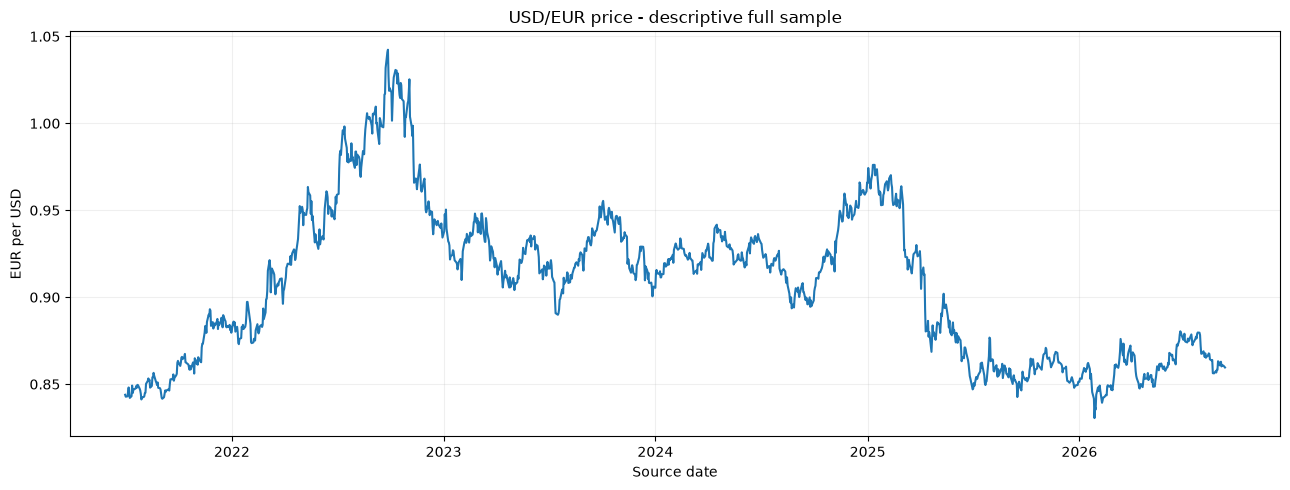

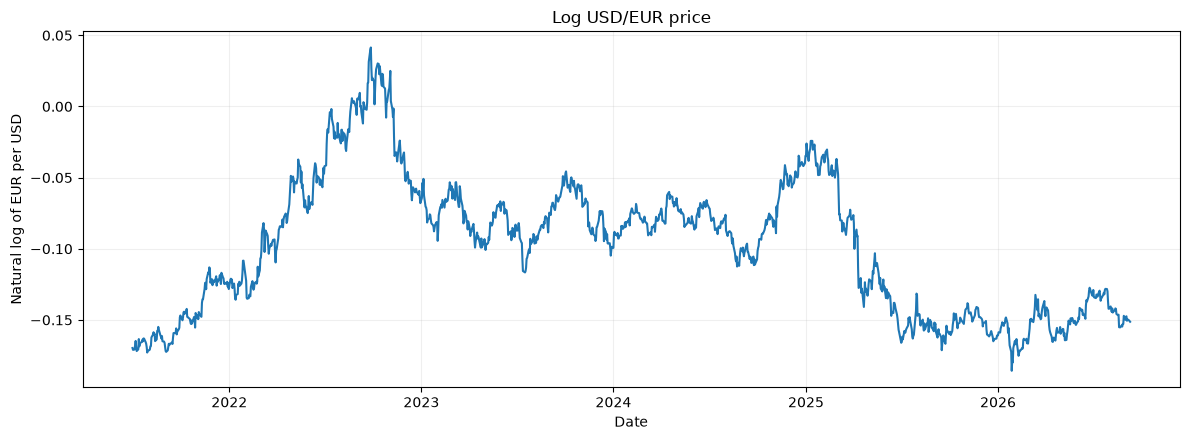

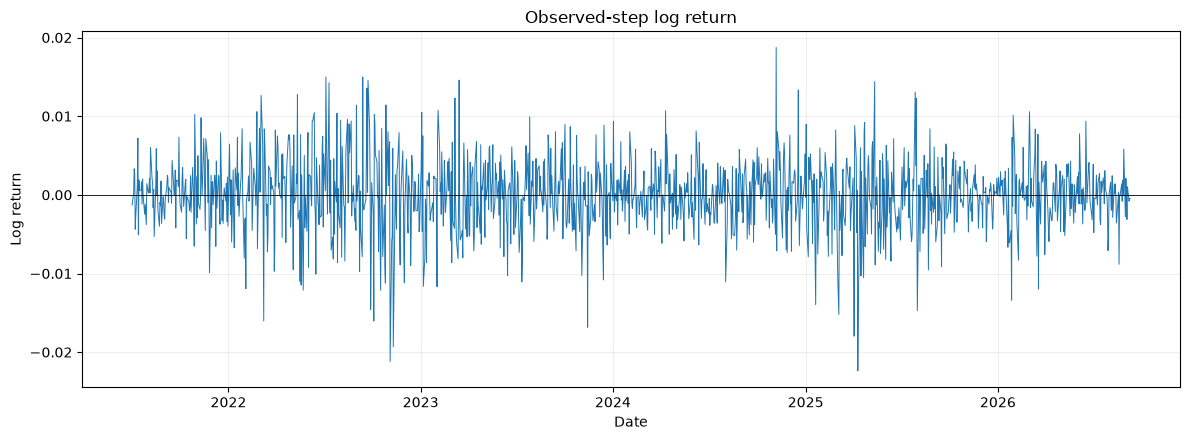

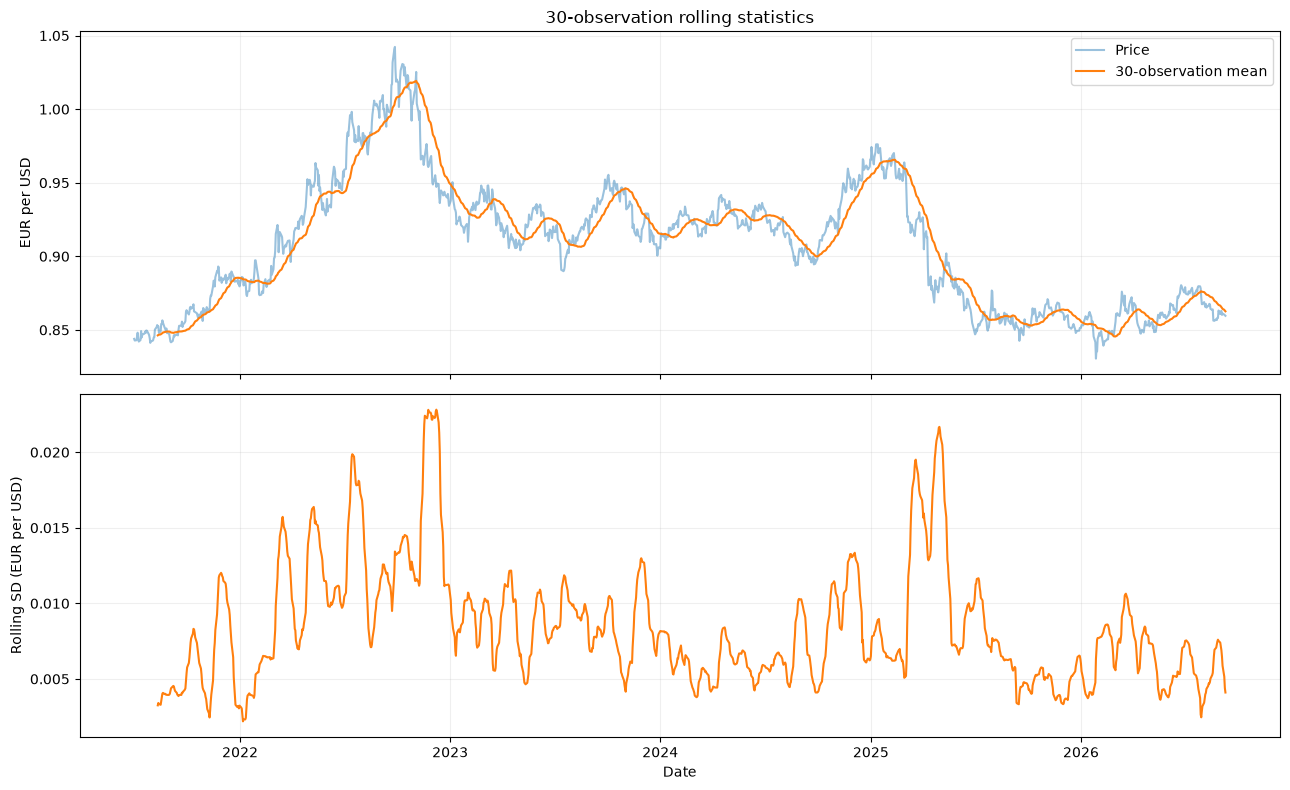

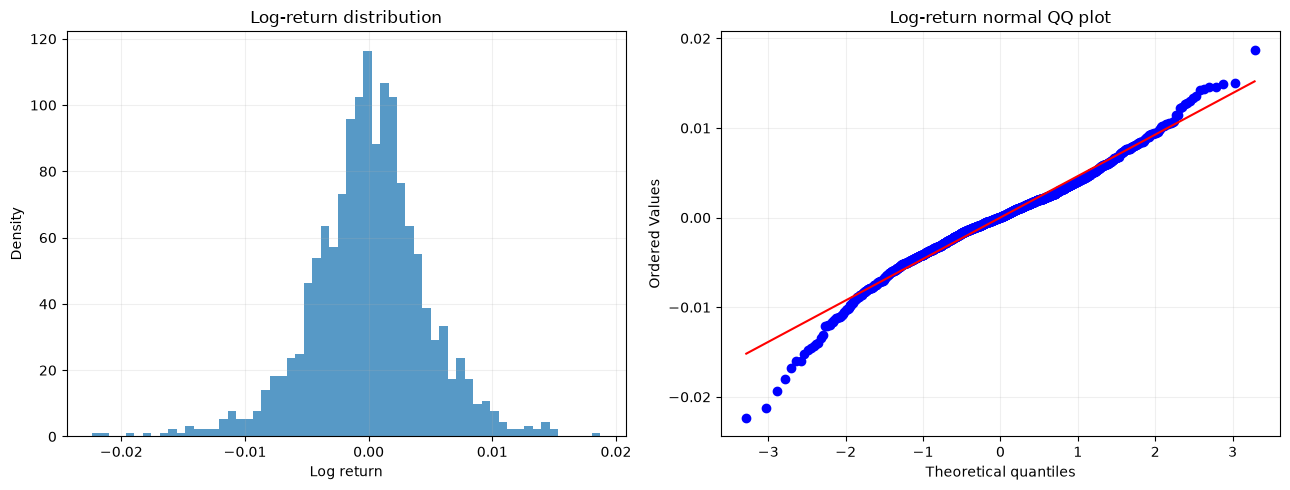

In [3]:
# Descriptive full-sample plots only; no model decisions use Test observations.
fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(df.index, df['Price'])
ax.set(title='USD/EUR price - descriptive full sample', ylabel=UNIT, xlabel='Source date')
save_figure(fig, '01_raw_price.png')

fig, ax = plt.subplots()
ax.plot(df.index, log_price)
ax.set(title='Log USD/EUR price', ylabel=f'Natural log of {UNIT}', xlabel='Date')
save_figure(fig, '02_log_price.png')

fig, ax = plt.subplots()
ax.plot(df.index[1:], returns[1:], linewidth=.7)
ax.axhline(0, color='black', linewidth=.6)
ax.set(title='Observed-step log return', ylabel='Log return', xlabel='Date')
save_figure(fig, '03_log_return.png')

fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharex=True)
axes[0].plot(df['Price'], alpha=.45, label='Price')
axes[0].plot(df['Price'].rolling(ROLLING_WINDOW).mean(), label=f'{ROLLING_WINDOW}-observation mean')
axes[0].set(title=f'{ROLLING_WINDOW}-observation rolling statistics', ylabel=UNIT); axes[0].legend()
axes[1].plot(df['Price'].rolling(ROLLING_WINDOW).std(), color='tab:orange')
axes[1].set(ylabel=f'Rolling SD ({UNIT})', xlabel='Date')
save_figure(fig, '04_rolling_stats.png')

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].hist(returns[1:], bins=60, density=True, alpha=.75)
axes[0].set(title='Log-return distribution', xlabel='Log return', ylabel='Density')
stats.probplot(returns[1:], dist='norm', plot=axes[1])
axes[1].set_title('Log-return normal QQ plot')
save_figure(fig, '05_return_distribution.png')


### Descriptive Statistics

Price and observed-step log return, reported separately for the full sample,
the first 80% (Train), and the final 20% (Test), using the notebook's raw
chronological split before scaling or windowing. Columns identify each sample;
rows give units, dates, Count, Mean, SD, Min, Q1, Median, Q3, Max, Skewness,
and Excess kurtosis.

SD uses `ddof=1`; skewness and excess kurtosis use pandas' bias-corrected
estimators (normal-distribution excess kurtosis = 0). Log returns are natural-log
changes, not percentages, across successive observed dates. The first full-sample
return is undefined and excluded. Returns belong to their ending date, so the
first Test return uses the last Train price. Calendar gaps are not filled.
Full-sample and Test statistics are descriptive reporting only, not inputs to
model selection or fitting. The tables below were calculated from the supplied
source data without rerunning model training.


In [ ]:
# Descriptive reporting only; this cell does not fit or configure a model.
def _make_descriptive_statistics(price, train_ratio):
    assert price.index.is_monotonic_increasing and price.index.is_unique
    assert price.notna().all() and np.isfinite(price).all() and price.gt(0).all()
    split = int(train_ratio * len(price))
    assert 0 < split < len(price)
    # Assign returns to their ending date; retain the Train-to-Test boundary return.
    log_return = np.log(price).diff()
    rows = []
    for variable, series, unit in [('Price', price, 'EUR per USD'),
                                    ('Log return', log_return, 'natural log; not percent')]:
        for sample, start, end in [('Full sample', 0, len(price)),
                                    ('Train', 0, split), ('Test', split, len(price))]:
            values = series.iloc[start:end].dropna()
            summary = values.describe(percentiles=[0.25, 0.5, 0.75])
            rows.append({'Variable': variable, 'Sample': sample, 'Unit': unit,
                'Start': str(values.index[0].date()), 'End': str(values.index[-1].date()),
                'Count': int(summary['count']), 'Mean': summary['mean'],
                'SD': summary['std'], 'Min': summary['min'], 'Q1': summary['25%'],
                'Median': summary['50%'], 'Q3': summary['75%'], 'Max': summary['max'],
                'Skewness': values.skew(), 'Excess kurtosis': values.kurt()})
    return pd.DataFrame(rows)

descriptive_statistics = _make_descriptive_statistics(df['Price'], TRAIN_RATIO)
del _make_descriptive_statistics
for _descriptive_variable in ['Price', 'Log return']:
    print(_descriptive_variable)
    display(descriptive_statistics.loc[
        descriptive_statistics['Variable'].eq(_descriptive_variable)
    ].drop(columns='Variable').set_index('Sample').T)
del _descriptive_variable


Price


Sample,Full sample,Train,Test
Unit,EUR per USD,EUR per USD,EUR per USD
Start,2021-07-01,2021-07-01,2025-08-27
End,2026-09-09,2025-08-26,2026-09-09
Count,1355,1084,271
Mean,0.907759,0.919844,0.859418
SD,0.04339,0.040014,0.009333
Min,0.8305,0.8412,0.8305
Q1,0.86525,0.89375,0.85285
Median,0.9136,0.9212,0.8594
Q3,0.93435,0.94245,0.8652


Log return


Sample,Full sample,Train,Test
Unit,natural log; not percent,natural log; not percent,natural log; not percent
Start,2021-07-02,2021-07-02,2025-08-27
End,2026-09-09,2025-08-26,2026-09-09
Count,1354,1083,271
Mean,0.000014,0.000016,0.000003
SD,0.004666,0.004927,0.003437
Min,-0.022368,-0.022368,-0.013396
Q1,-0.002571,-0.002723,-0.002022
Median,0.000109,0.000109,0.000116
Q3,0.002583,0.002724,0.002068


## Step 3 - Raw chronological Train 80% / Test 20% split

Split the sorted raw observations without shuffling. Report exact counts/dates; no validation subset.

,partition,rows,start_date,end_date
0,Train,1084,2021-07-01,2025-08-26
1,Test,271,2025-08-27,2026-09-09


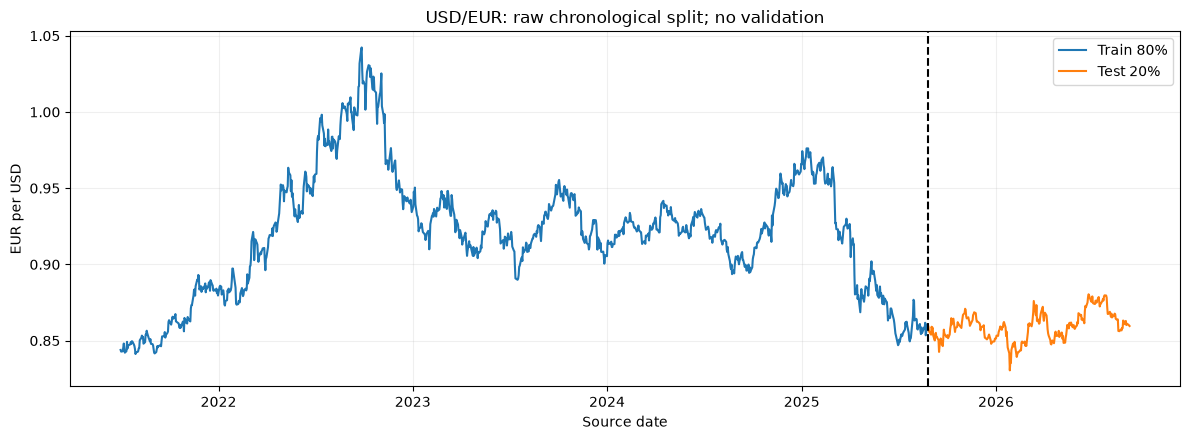

In [4]:
n_train = int(TRAIN_RATIO * n)
n_test = n - n_train
T = n_train - 1
check('Chronological raw 80/20 partition', df.index.is_monotonic_increasing and df.index.is_unique and n_train == int(.8*n),
      'No shuffling, validation partition, or target imputation.')
check('Sufficient Train/Test history', n_train > MAX_H + max(DIAGNOSTIC_LAGS) + 10 and n_test >= MAX_H,
      'Requested horizons and diagnostic lags must remain feasible without shortening.')
split_summary = pd.DataFrame([dict(partition=label, rows=b-a, start_date=df.index[a], end_date=df.index[b-1])
                             for label,a,b in [('Train',0,n_train),('Test',n_train,n)]])
save_table(split_summary, 'split_summary.csv')
display(split_summary)
fig, ax = plt.subplots()
ax.plot(df.index[:n_train], prices[:n_train], label='Train 80%')
ax.plot(df.index[n_train:], prices[n_train:], label='Test 20%')
ax.axvline(df.index[n_train], color='black', linestyle='--')
ax.set(title=f'{ASSET_NAME}: raw chronological split; no validation', ylabel=UNIT, xlabel='Source date')
ax.legend(); save_figure(fig, '01_raw_split.png')

## Step 4 - Train-only stationarity and differencing

Choose the smallest d in 0..2 supported jointly by ADF (p < 0.05) and KPSS (p > 0.05). Test is not used.

In [5]:
train_log = log_price[:n_train]
stationarity_rows=[]
d=None
for candidate_d in range(SETTINGS['max_d']+1):
    values=np.diff(train_log,n=candidate_d) if candidate_d else train_log
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter('always')
        adf=adfuller(values,autolag='AIC')
        kp=kpss(values,regression='c',nlags='auto')
    supported=adf[1]<ALPHA and kp[1]>ALPHA
    stationarity_rows.extend([
        dict(d=candidate_d,test='ADF',statistic=adf[0],p_value=adf[1],status='PASS' if adf[1]<ALPHA else 'FAIL', interpretation='H0: unit root',warnings=warning_text(caught)),
        dict(d=candidate_d,test='KPSS',statistic=kp[0],p_value=kp[1],status='PASS' if kp[1]>ALPHA else 'FAIL', interpretation='H0: stationarity; p may be table bound',warnings=warning_text(caught))])
    if supported:
        d=candidate_d
        break
stationarity_tests=pd.DataFrame(stationarity_rows)
save_table(stationarity_tests,'stationarity_tests.csv'); display(stationarity_tests)
check('Train stationarity supports differencing', d is not None,
      'Smallest d jointly supported by ADF and KPSS; no Test-based changes.', statistic=d)


,d,test,statistic,p_value,status,interpretation,warnings
0,0,ADF,-2.064543,0.259009,FAIL,H0: unit root,FutureWarning: adfuller currently returns a pl...
1,0,KPSS,0.586454,0.023868,FAIL,H0: stationarity; p may be table bound,FutureWarning: adfuller currently returns a pl...
2,1,ADF,-24.338016,0.000000,PASS,H0: unit root,FutureWarning: adfuller currently returns a pl...
3,1,KPSS,0.310112,0.100000,PASS,H0: stationarity; p may be table bound,FutureWarning: adfuller currently returns a pl...


## Step 5 - Train-only identification and AIC shortlist

Plot Train ACF/PACF. Search p,q=0..5 with trends valid for the Train-supported d, using the same ARIMA.fit() defaults as S&P. Keep the Top 3 converged finite-AIC fits before residual/root gates. The following auto_arima cross-check is supplementary and cannot replace this selection rule.

**AIC Rank:** อันดับเริ่มจาก 1 เฉพาะโมเดลที่ converged, AIC finite และไม่มี fit error เรียง AIC จากน้อยไปมาก แล้วใช้ BIC และชื่อโมเดลเมื่อค่าเท่ากัน ตารางด้านล่างแสดง **Top 5** เพื่อเปรียบเทียบ โดยยังใช้ **Top 3** สำหรับการเลือกโมเดลใน Step 6 ตามกติกาเดิมของ notebook นี้ ไม่เปลี่ยนผลพยากรณ์


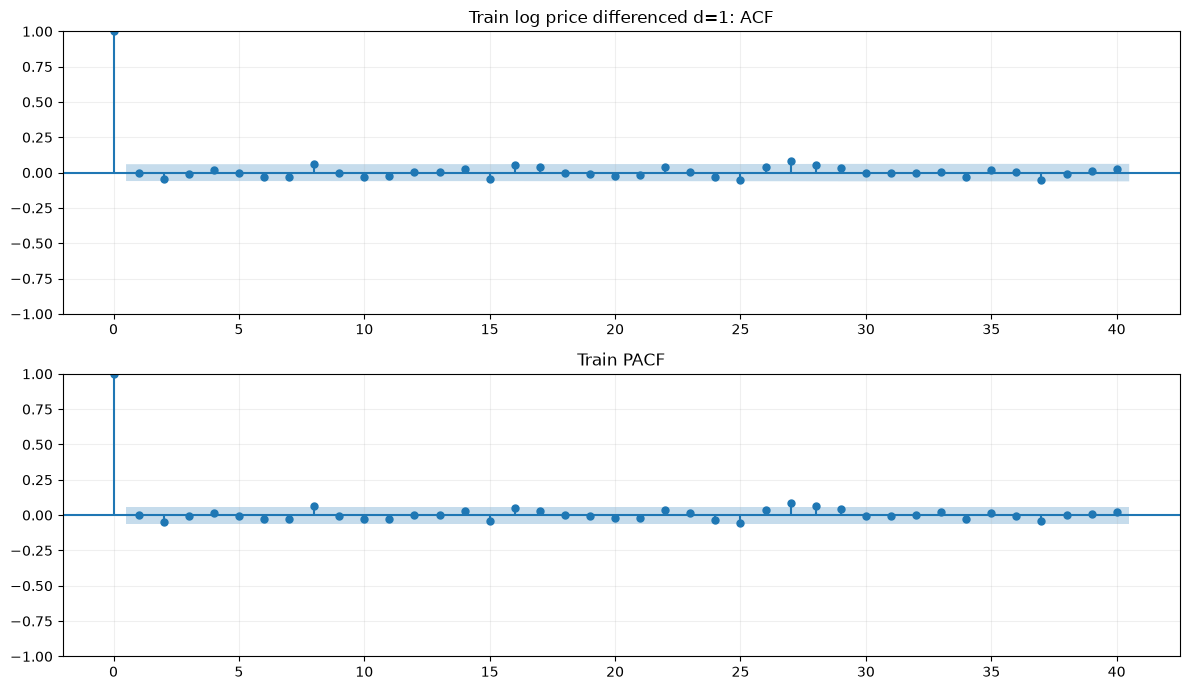

Completed Train ARIMA grid p=0


Completed Train ARIMA grid p=1


Completed Train ARIMA grid p=2


Completed Train ARIMA grid p=3


Completed Train ARIMA grid p=4


Completed Train ARIMA grid p=5


AIC Rank,model,p,d,q,trend,AIC,BIC,converged,warnings,error
1,"ARIMA(2,1,0), trend=n",2,1,0,n,-8431.940115,-8416.977645,True,,
2,"ARIMA(0,1,2), trend=n",0,1,2,n,-8431.880629,-8416.918158,True,,
3,"ARIMA(1,1,0), trend=n",1,1,0,n,-8431.527391,-8421.552411,True,,
4,"ARIMA(0,1,1), trend=n",0,1,1,n,-8431.526231,-8421.551250,True,,
5,"ARIMA(3,1,0), trend=n",3,1,0,n,-8430.023159,-8410.073198,True,,


In [6]:
fig,axes=plt.subplots(2,1,figsize=(12,7))
plot_acf(values,lags=40,ax=axes[0]); plot_pacf(values,lags=40,method='ywm',ax=axes[1])
axes[0].set_title(f'Train log price differenced d={d}: ACF')
axes[1].set_title('Train PACF'); save_figure(fig,'03_train_acf_pacf.png')
# Match BTC/S&P: shortlist by AIC BEFORE applying residual/root gates.
trends = ['n', 'c'] if d == 0 else (['n', 't'] if d == 1 else ['n'])
grid_rows, fitted_models = [], {}
for p in range(SETTINGS['max_p'] + 1):
    for q in range(SETTINGS['max_q'] + 1):
        for trend in trends:
            label = f'ARIMA({p},{d},{q}), trend={trend}'
            row = dict(model=label, p=p, d=d, q=q, trend=trend, AIC=np.nan,
                       BIC=np.nan, converged=False, roots_valid=False, warnings='', error='')
            caught = []
            try:
                with warnings.catch_warnings(record=True) as caught:
                    warnings.simplefilter('always')
                    result = ARIMA(train_log, order=(p, d, q), trend=trend).fit()
                    # Root properties may emit RuntimeWarning; capture them with this fit.
                    roots = np.r_[result.arroots, result.maroots]
                row.update(AIC=result.aic, BIC=result.bic,
                    converged=bool(result.mle_retvals.get('converged', False)),
                    roots_valid=bool(np.isfinite(roots).all() and (np.abs(roots) > 1).all()))
                fitted_models[label] = result
            except Exception as exc:
                row['error'] = f'{type(exc).__name__}: {exc}'
            row['warnings'] = warning_text(caught)
            grid_rows.append(row)
    print(f'Completed Train ARIMA grid p={p}', flush=True)

grid = pd.DataFrame(grid_rows).sort_values(['AIC', 'BIC', 'model'], na_position='last').reset_index(drop=True)
# Sequential AIC ranks among converged, finite-AIC, error-free Train fits.
eligible_mask = grid.converged & np.isfinite(grid.AIC) & grid.error.eq('')
grid.insert(0, 'AIC Rank', pd.Series(pd.NA, index=grid.index, dtype='Int64'))
grid.loc[eligible_mask, 'AIC Rank'] = np.arange(1, int(eligible_mask.sum()) + 1)
save_table(grid, 'arima_grid.csv')
eligible = grid.loc[eligible_mask].copy()
check('At least three converged finite-AIC Train candidates', len(eligible) >= SETTINGS['top_k'],
      'Shortlist by AIC first; roots and Ljung-Box are checked on these three fits.')
top = eligible.head(SETTINGS['top_k']).copy()
save_table(top, 'arima_top_candidates.csv')
# Show Top 5 for comparison; the original Top 3 selection is unchanged.
aic_rank_preview = eligible.head(5).loc[:, ['AIC Rank', 'model', 'p', 'd', 'q', 'trend', 'AIC', 'BIC', 'converged', 'warnings', 'error']].copy()
display(aic_rank_preview.style.format({'AIC': '{:.6f}', 'BIC': '{:.6f}'}).hide(axis='index'))


In [7]:
# Supplementary Train-only cross-check; does not select or replace the final model.
cross_rows = []
for intercept in ([False, True] if d <= 1 else [False]):
    caught = []
    row = dict(with_intercept=intercept, order='', AIC=np.nan, BIC=np.nan,
               converged=False, warnings='', error='')
    try:
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter('always')
            cross = pm.auto_arima(train_log, d=d, seasonal=False, stepwise=False,
                information_criterion='aic', start_p=0, start_q=0,
                max_p=SETTINGS['max_p'], max_q=SETTINGS['max_q'], max_order=None,
                with_intercept=intercept, suppress_warnings=False, error_action='warn', n_jobs=1)
        row.update(order=str(cross.order), AIC=cross.aic(), BIC=cross.bic(),
                   converged=bool(cross.arima_res_.mle_retvals.get('converged', False)))
    except Exception as exc:
        row['error'] = f'{type(exc).__name__}: {exc}'
    row['warnings'] = warning_text(caught)
    cross_rows.append(row)
    print(f'auto_arima Train cross-check complete: with_intercept={intercept}', flush=True)
cross_check = pd.DataFrame(cross_rows)
save_table(cross_check, 'auto_arima_cross_check.csv')
display(cross_check)
check('Train auto_arima cross-check completed', cross_check.error.eq('').all(),
      'Supplementary evidence only; likelihood/trend conventions may differ from statsmodels.')


auto_arima Train cross-check complete: with_intercept=False


auto_arima Train cross-check complete: with_intercept=True


,with_intercept,order,AIC,BIC,converged,warnings,error
0,False,"(0, 1, 0)",-8433.526573,-8428.539083,False,ConvergenceWarning: Maximum Likelihood optimiz...,
1,True,"(0, 1, 0)",-8431.539014,-8421.564034,False,ConvergenceWarning: Maximum Likelihood optimiz...,


## Step 6 - Train residual diagnostics and final model

Remove initialization burn-in. Require Ljung-Box p > 0.05 at lags 10/20/30 with model_df=p+q and existing roots outside the unit circle. Choose the lowest-AIC passing Top 3 candidate; stop if none passes. Mean, ARCH, normality and significance are reporting-only. When ARCH is significant, compute robust covariance for reporting while keeping the original forecast parameters.

C:\Users\User\anaconda3\envs\vs_nine_tf\Lib\site-packages\statsmodels\stats\diagnostic.py:997: FutureWarning: acorr_lm currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an LMTestResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  return acorr_lm(
C:\Users\User\anaconda3\envs\vs_nine_tf\Lib\site-packages\statsmodels\stats\diagnostic.py:997: FutureWarning: acorr_lm currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an LMTestResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  return acorr_lm(


C:\Users\User\anaconda3\envs\vs_nine_tf\Lib\site-packages\statsmodels\stats\diagnostic.py:997: FutureWarning: acorr_lm currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an LMTestResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  return acorr_lm(


,model,AIC,ljung_box_pass,roots_pass,arch_pvalue
0,"ARIMA(2,1,0), trend=n",-8431.940115,True,True,5.478869e-10
1,"ARIMA(0,1,2), trend=n",-8431.880629,True,True,5.169483e-10
2,"ARIMA(1,1,0), trend=n",-8431.527391,True,True,3.393106e-10


,model,test,statistic,p_value,pass_fail,note
0,"ARIMA(2,1,0), trend=n",Ljung-Box lag 10,7.246233,5.103141e-01,PASS,model_df=2
1,"ARIMA(2,1,0), trend=n",Ljung-Box lag 20,16.859867,5.327587e-01,PASS,model_df=2
2,"ARIMA(2,1,0), trend=n",Ljung-Box lag 30,37.137852,1.158514e-01,PASS,model_df=2
3,"ARIMA(2,1,0), trend=n",Mean = 0 (t-test),0.112871,9.101540e-01,PASS,Residual mean=1.68801e-05
4,"ARIMA(2,1,0), trend=n",ARCH LM (10 lags),64.315324,5.478869e-10,FAIL,
5,"ARIMA(2,1,0), trend=n",Jarque-Bera,124.890548,7.592101e-28,FAIL,"skew=-0.2611, kurtosis=4.5795"
6,"ARIMA(2,1,0), trend=n",AR roots outside unit circle,4.598373,NaN,PASS,All |root|>1: True
7,"ARIMA(2,1,0), trend=n",MA roots outside unit circle,NaN,NaN,REPORTED,N/A: no roots
8,"ARIMA(2,1,0), trend=n",Parameter significance: ar.L1,-0.000571,9.817400e-01,FAIL,"Report only; estimate in statistic column, sig..."
9,"ARIMA(2,1,0), trend=n",Parameter significance: ar.L2,-0.047292,8.472739e-02,FAIL,"Report only; estimate in statistic column, sig..."


Selected: ARIMA(2,1,0), trend=n


,model,parameter,estimate,standard_error,p_value,significant,covariance
0,"ARIMA(2,1,0), trend=n",ar.L1,-0.000571,2.494634e-02,9.817400e-01,False,opg
1,"ARIMA(2,1,0), trend=n",ar.L2,-0.047292,2.743352e-02,8.472739e-02,False,opg
2,"ARIMA(2,1,0), trend=n",sigma2,0.000024,7.777806e-07,5.779496e-212,True,opg


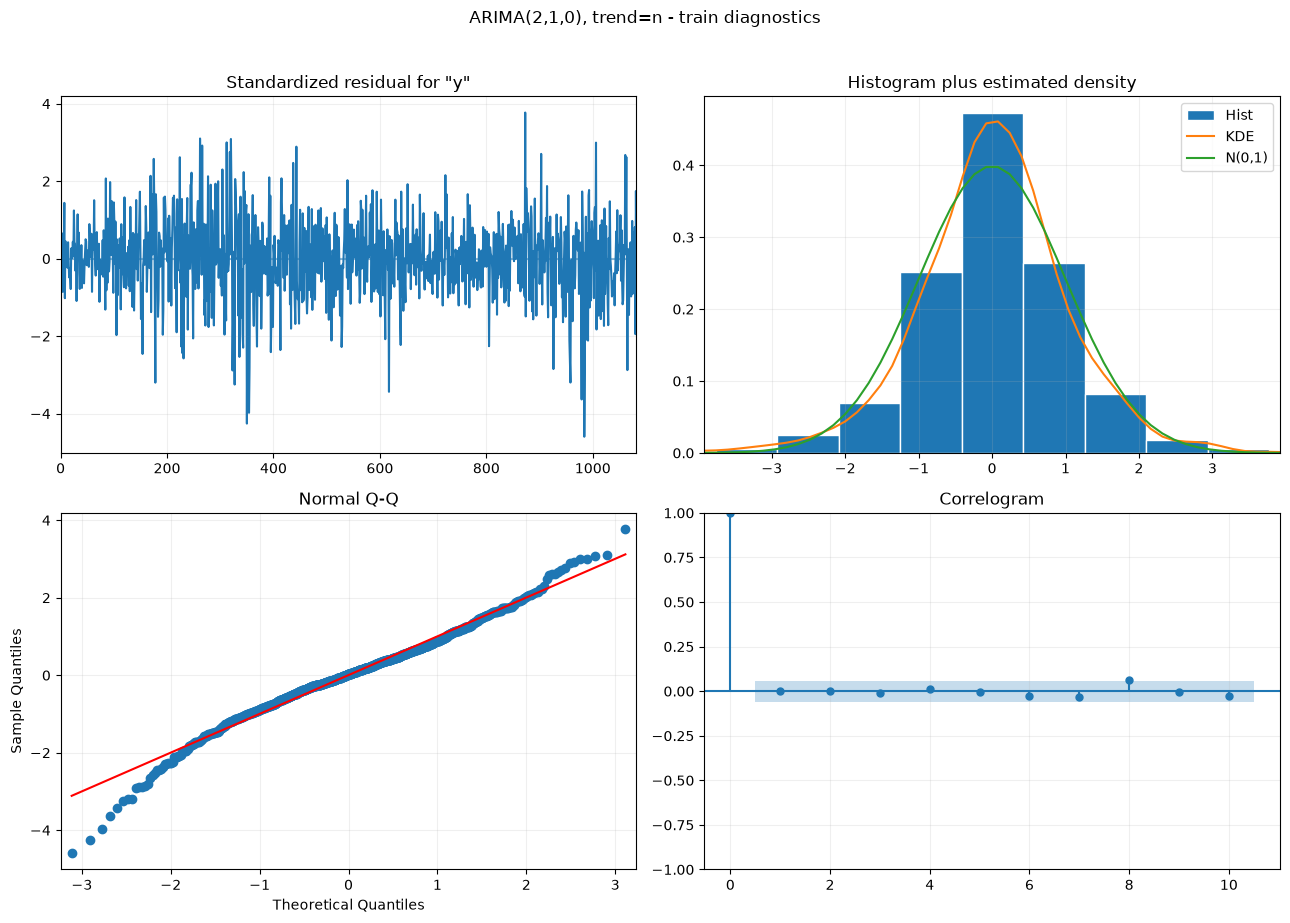

,model,parameter,estimate,robust_standard_error,robust_p_value,converged,warnings
0,"ARIMA(2,1,0), trend=n",ar.L1,-0.000571,0.036936,9.876669e-01,True,
1,"ARIMA(2,1,0), trend=n",ar.L2,-0.047292,0.033681,1.602770e-01,True,
2,"ARIMA(2,1,0), trend=n",sigma2,0.000024,0.000001,1.191629e-67,True,


                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                 1084
Model:                 ARIMA(2, 1, 0)   Log Likelihood                4218.970
Date:                Tue, 27 Oct 2026   AIC                          -8431.940
Time:                        11:02:05   BIC                          -8416.978
Sample:                             0   HQIC                         -8426.275
                               - 1084                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.0006      0.025     -0.023      0.982      -0.049       0.048
ar.L2         -0.0473      0.027     -1.724      0.085      -0.101       0.006
sigma2      2.417e-05   7.78e-07     31.072      0.0

In [8]:
check_rows, parameter_rows, root_rows, candidate_status = [], [], [], []
robust_results, robust_rows, robust_warning_messages = {}, [], {}
def add_check(model, test, statistic=np.nan, p_value=np.nan, passed=None, note=''):
    check_rows.append(dict(model=model, test=test, statistic=statistic, p_value=p_value,
                           pass_fail='REPORTED' if passed is None else ('PASS' if passed else 'FAIL'), note=note))

for item in top.itertuples(index=False):
    result = fitted_models[item.model]
    burn_in = max(d, int(result.loglikelihood_burn), int(getattr(result.filter_results, 'nobs_diffuse', 0)))
    residuals = pd.Series(np.asarray(result.resid)[burn_in:]).dropna()
    assert min(DIAGNOSTIC_LAGS) > item.p + item.q and len(residuals) > max(DIAGNOSTIC_LAGS)
    lb = acorr_ljungbox(residuals, lags=DIAGNOSTIC_LAGS, model_df=item.p + item.q, return_df=True)
    lb_pass = bool(lb['lb_pvalue'].notna().all() and (lb['lb_pvalue'] > ALPHA).all())
    for lag, row in lb.iterrows():
        add_check(item.model, f'Ljung-Box lag {lag}', row['lb_stat'], row['lb_pvalue'],
                  bool(row['lb_pvalue'] > ALPHA), f'model_df={item.p + item.q}')
    mean_stat, mean_p = stats.ttest_1samp(residuals, 0)
    add_check(item.model, 'Mean = 0 (t-test)', mean_stat, mean_p, mean_p > ALPHA,
              f'Residual mean={residuals.mean():.6g}')
    arch_stat, arch_p, _, _ = het_arch(residuals, nlags=10)
    add_check(item.model, 'ARCH LM (10 lags)', arch_stat, arch_p, arch_p > ALPHA)
    if arch_p <= ALPHA:
        with warnings.catch_warnings(record=True) as robust_caught:
            warnings.simplefilter('always')
            robust = ARIMA(train_log, order=(item.p, d, item.q), trend=item.trend).fit(cov_type='robust')
        robust_results[item.model] = robust
        robust_warning_messages[item.model] = warning_text(robust_caught)
        for name, coef, se, pv in zip(robust.param_names, robust.params, robust.bse, robust.pvalues):
            robust_rows.append(dict(model=item.model, parameter=name, estimate=coef,
                robust_standard_error=se, robust_p_value=pv,
                converged=bool(robust.mle_retvals.get('converged', False)),
                warnings=warning_text(robust_caught)))
    jb_stat, jb_p, skew, kurt = jarque_bera(residuals)
    add_check(item.model, 'Jarque-Bera', jb_stat, jb_p, jb_p > ALPHA,
              f'skew={skew:.4f}, kurtosis={kurt:.4f}')
    roots_pass = True
    for kind, roots in [('AR', result.arroots), ('MA', result.maroots)]:
        moduli = np.abs(roots)
        passed = bool(np.isfinite(moduli).all() and (moduli > 1).all())
        roots_pass &= passed
        add_check(item.model, f'{kind} roots outside unit circle',
                  moduli.min() if len(moduli) else np.nan, passed=passed if len(moduli) else None,
                  note='N/A: no roots' if not len(moduli) else f'All |root|>1: {passed}')
        for j, root in enumerate(roots, 1):
            root_rows.append(dict(model=item.model, kind=kind, root_number=j,
                                  real=root.real, imag=root.imag, modulus=abs(root), outside=abs(root) > 1))
    for name, coef, se, pv in zip(result.param_names, result.params, result.bse, result.pvalues):
        parameter_rows.append(dict(model=item.model, parameter=name, estimate=coef, standard_error=se,
                                   p_value=pv, significant=pv < ALPHA, covariance=result.cov_type))
        add_check(item.model, f'Parameter significance: {name}', coef, pv, pv < ALPHA,
                  'Report only; estimate in statistic column, significance uses p < alpha')
    candidate_status.append(dict(model=item.model, AIC=item.AIC, ljung_box_pass=lb_pass,
                                 roots_pass=roots_pass, arch_pvalue=arch_p))

assumption_checks = pd.DataFrame(check_rows)
parameter_significance = pd.DataFrame(parameter_rows)
candidate_diagnostics = pd.DataFrame(candidate_status).sort_values('AIC')
save_table(assumption_checks, 'assumption_checks.csv')
save_table(parameter_significance, 'parameter_significance.csv')
save_table(pd.DataFrame(root_rows, columns=['model','kind','root_number','real','imag','modulus','outside']), 'model_roots.csv')
save_table(candidate_diagnostics, 'candidate_diagnostics.csv')
if robust_rows:
    save_table(pd.DataFrame(robust_rows), 'robust_parameter_significance.csv')
display(candidate_diagnostics)
display(assumption_checks)
passing = candidate_diagnostics.loc[candidate_diagnostics['ljung_box_pass'] & candidate_diagnostics['roots_pass']]
check('Top-3 Train candidate passes Ljung-Box and roots', not passing.empty,
      'Stop if none passes; no Test-based fallback or gate relaxation.')
final_label = passing.iloc[0]['model']
final_spec = top.set_index('model', drop=False).loc[final_label]
selected = final_spec
res = fitted_models[final_label]  # reuse original train fit; frozen forecast parameters
frozen_params = np.asarray(res.params).copy()
assert res.nobs == n_train
print('Selected:', final_label)
display(parameter_significance.loc[parameter_significance['model'].eq(final_label)])
fig = res.plot_diagnostics(figsize=(13, 9))
fig.suptitle(f'{final_label} - train diagnostics', y=1.02)
save_figure(fig, '08_residual_diagnostics.png')

summary_text = res.summary().as_text()
robust_res = None
if passing.iloc[0]['arch_pvalue'] <= ALPHA:
    robust_res = robust_results[final_label]
    display(pd.DataFrame(robust_rows).loc[lambda x: x['model'].eq(final_label)])
    summary_text += '\n\nROBUST COVARIANCE REFIT ON TRAIN - reporting only; forecasts retain original parameters.\n'
    summary_text += robust_res.summary().as_text()
    summary_text += '\nWarnings: ' + robust_warning_messages[final_label]
    summary_text += '\nRobust refit converged: ' + str(robust_res.mle_retvals.get('converged', False))
assert np.array_equal(np.asarray(res.params), frozen_params)
print(summary_text)
# Report-only robust fits must never replace the original forecasting parameters.
np.testing.assert_array_equal(np.asarray(res.params), frozen_params)
save_table(parameter_significance, 'arima_parameters.csv')
save_table(notebook_tables['model_roots.csv'], 'arima_roots.csv')
train_diagnostics = assumption_checks.copy()
save_table(train_diagnostics, 'train_residual_diagnostics.csv')
res.save(MODEL_DIR / 'arima_train.pkl')
write_json(MODEL_DIR / 'selected_order.json', dict(order=[int(selected.p), d, int(selected.q)],
    trend=selected.trend, parameters=frozen_params.tolist(), fit_end_date=df.index[T], fit_n=n_train,
    selection=SETTINGS['selection'], top_k=SETTINGS['top_k'], diagnostic_lags=DIAGNOSTIC_LAGS, alpha=ALPHA))
(SUMMARY_DIR / 'model_summary.txt').write_text(summary_text, encoding='utf-8')
if robust_res is not None:
    robust_res.save(MODEL_DIR / 'arima_train_robust_reporting_only.pkl')
def model_fingerprint(): return hashlib.sha256(np.asarray(res.params).tobytes()).hexdigest()
frozen_state = model_fingerprint()


## Step 7 - Forecast values by horizon

Rolling-origin Test forecasts use observations through each origin, with Train coefficients frozen. Targets follow observed row positions. Point forecasts and model-based 95% intervals are in EUR per USD; exponentiated log forecasts are conditional medians.

In [9]:
forecast_rows=[]
for origin in range(T,n-1):
    # Refilter the history available at this origin; coefficients and variance stay frozen.
    state=res.apply(log_price[:origin+1],refit=False)
    np.testing.assert_array_equal(np.asarray(state.params),frozen_params)
    prediction=state.get_forecast(steps=MAX_H)
    mean=np.asarray(prediction.predicted_mean)
    bounds=np.asarray(prediction.conf_int(alpha=ALPHA))
    for h in HORIZONS:
        if origin+h<n:
            forecast_rows.append(dict(h=h,origin_index=origin,target_index=origin+h,
                origin_date=df.index[origin],target_date=df.index[origin+h],price_origin=prices[origin],actual=prices[origin+h],
                forecast=np.exp(mean[h-1]),lower95=np.exp(bounds[h-1,0]),upper95=np.exp(bounds[h-1,1]),
                predicted_log_return=mean[h-1]-log_price[origin]))
forecasts=pd.DataFrame(forecast_rows)
seed_forecasts={}

### 7.2 Full historical Test forecast tables by horizon

Display and export every aligned origin/target/actual/forecast/interval row.

In [10]:
save_table(forecasts,'test_forecasts_all.csv')
for h in HORIZONS:
    group=forecasts.loc[forecasts.h.eq(h)].copy()
    save_table(group,f'forecasts_h{h}.csv')
    display(Markdown(f'### Historical Test forecasts: h={h} observations ({UNIT})'))
    show_table(group.drop(columns=['origin_index','target_index','predicted_log_return']))

### Historical Test forecasts: h=1 observations (EUR per USD)

h,origin_date,target_date,price_origin,actual,forecast,lower95,upper95
1,2025-08-26,2025-08-27,0.859000,0.859200,0.858660,0.850426,0.866973
1,2025-08-27,2025-08-28,0.859200,0.856000,0.859280,0.851041,0.867600
1,2025-08-28,2025-08-29,0.856000,0.855800,0.855992,0.847784,0.864280
1,2025-08-29,2025-09-01,0.855800,0.853900,0.855951,0.847743,0.864238
1,2025-09-01,2025-09-02,0.853900,0.859100,0.853911,0.845722,0.862178
1,2025-09-02,2025-09-03,0.859100,0.857600,0.859187,0.850949,0.867506
1,2025-09-03,2025-09-04,0.857600,0.858500,0.857355,0.849134,0.865655
1,2025-09-04,2025-09-05,0.858500,0.853400,0.858570,0.850338,0.866883
1,2025-09-05,2025-09-08,0.853400,0.850100,0.853361,0.845178,0.861623
1,2025-09-08,2025-09-09,0.850100,0.854200,0.850341,0.842188,0.858574


### Historical Test forecasts: h=3 observations (EUR per USD)

h,origin_date,target_date,price_origin,actual,forecast,lower95,upper95
3,2025-08-26,2025-08-29,0.859000,0.855800,0.858756,0.844768,0.872977
3,2025-08-27,2025-09-01,0.859200,0.853900,0.859267,0.845270,0.873496
3,2025-08-28,2025-09-02,0.856000,0.859100,0.856144,0.842198,0.870321
3,2025-08-29,2025-09-03,0.855800,0.857600,0.855953,0.842010,0.870127
3,2025-09-01,2025-09-04,0.853900,0.858500,0.854000,0.840089,0.868141
3,2025-09-02,2025-09-05,0.859100,0.853400,0.858937,0.844945,0.873160
3,2025-09-03,2025-09-08,0.857600,0.850100,0.857437,0.843470,0.871636
3,2025-09-04,2025-09-09,0.858500,0.854200,0.858525,0.844540,0.872741
3,2025-09-05,2025-09-10,0.853400,0.855100,0.853603,0.839698,0.867738
3,2025-09-08,2025-09-11,0.850100,0.852300,0.850486,0.836632,0.864569


### Historical Test forecasts: h=5 observations (EUR per USD)

...

h,origin_date,target_date,price_origin,actual,forecast,lower95,upper95
14,2025-08-26,2025-09-15,0.859000,0.850300,0.858752,0.829520,0.889014
14,2025-08-27,2025-09-16,0.859200,0.842600,0.859268,0.830018,0.889548
14,2025-08-28,2025-09-17,0.856000,0.846600,0.856137,0.826994,0.886307
14,2025-08-29,2025-09-18,0.855800,0.848400,0.855953,0.826817,0.886117
14,2025-09-01,2025-09-19,0.853900,0.851400,0.853996,0.824926,0.884090
14,2025-09-02,2025-09-22,0.859100,0.847200,0.858948,0.829709,0.889217
14,2025-09-03,2025-09-23,0.857600,0.846400,0.857433,0.828246,0.887649
14,2025-09-04,2025-09-24,0.858500,0.851900,0.858527,0.829302,0.888781
14,2025-09-05,2025-09-25,0.853400,0.857200,0.853592,0.824536,0.883672
14,2025-09-08,2025-09-26,0.850100,0.854600,0.850479,0.821529,0.880450


### Historical Test forecasts: h=21 observations (EUR per USD)

h,origin_date,target_date,price_origin,actual,forecast,lower95,upper95
21,2025-08-26,2025-09-24,0.859000,0.851900,0.858752,0.823165,0.895877
21,2025-08-27,2025-09-25,0.859200,0.857200,0.859268,0.823659,0.896415
21,2025-08-28,2025-09-26,0.856000,0.854600,0.856137,0.820658,0.893149
21,2025-08-29,2025-09-29,0.855800,0.852800,0.855953,0.820482,0.892958
21,2025-09-01,2025-09-30,0.853900,0.852300,0.853996,0.818606,0.890916
21,2025-09-02,2025-10-01,0.859100,0.852500,0.858948,0.823353,0.896082
21,2025-09-03,2025-10-02,0.857600,0.853600,0.857433,0.821901,0.894502
21,2025-09-04,2025-10-03,0.858500,0.851600,0.858527,0.822949,0.895642
21,2025-09-05,2025-10-06,0.853400,0.854000,0.853592,0.818219,0.890494
21,2025-09-08,2025-10-07,0.850100,0.857900,0.850479,0.815235,0.887247


### Historical Test forecasts: h=30 observations (EUR per USD)

h,origin_date,target_date,price_origin,actual,forecast,lower95,upper95
30,2025-08-26,2025-10-07,0.859000,0.857900,0.858752,0.816446,0.903250
30,2025-08-27,2025-10-08,0.859200,0.860000,0.859268,0.816936,0.903793
30,2025-08-28,2025-10-09,0.856000,0.864700,0.856137,0.813960,0.900500
30,2025-08-29,2025-10-10,0.855800,0.860600,0.855953,0.813785,0.900307
30,2025-09-01,2025-10-13,0.853900,0.864400,0.853996,0.811924,0.898248
30,2025-09-02,2025-10-14,0.859100,0.861600,0.858948,0.816632,0.903456
30,2025-09-03,2025-10-15,0.857600,0.858600,0.857433,0.815192,0.901863
30,2025-09-04,2025-10-16,0.858500,0.855700,0.858527,0.816232,0.903013
30,2025-09-05,2025-10-17,0.853400,0.858300,0.853592,0.811540,0.897823
30,2025-09-08,2025-10-20,0.850100,0.859000,0.850479,0.808581,0.894549


### 7.3 Future forecasts from the latest observed date

Use the same Train parameters with updated filtering states. All horizons share the latest origin; projected dates follow the source weekday pattern.

In [11]:
# These are projected source-calendar dates, not verified exchange/holiday sessions.
future_dates=pd.date_range(df.index[-1]+calendar_offset,periods=MAX_H,freq=calendar_offset)
future_rows=[]
latest_state=res.apply(log_price,refit=False)
np.testing.assert_array_equal(latest_state.params,frozen_params)
fc=latest_state.get_forecast(steps=MAX_H)
means=np.asarray(fc.predicted_mean); intervals=np.asarray(fc.conf_int(alpha=ALPHA))
for h in HORIZONS:
    future_rows.append(dict(h=h,origin_date=df.index[-1],target_date=future_dates[h-1],
        target_date_status='PROJECTED: weekday pattern, holidays/omissions unknown',price_origin=prices[-1],
        forecast=np.exp(means[h-1]),lower95=np.exp(intervals[h-1,0]),upper95=np.exp(intervals[h-1,1])))
future_forecasts=pd.DataFrame(future_rows)
save_table(future_forecasts,'future_forecasts.csv')
display(Markdown('### Future forecasts: common latest origin; original Train fit'))
show_table(future_forecasts)
print('Future values have no actuals or metrics. Forecasts count future observations; displayed dates are conditional projections.')
check('Fitted model and preprocessing remain frozen', model_fingerprint()==frozen_state,
      'Original Train ARIMA coefficients are unchanged during Test and future filtering.')
write_json(MODEL_DIR/'frozen_state_audit.json',dict(before=frozen_state,after=model_fingerprint(),
    original_fit_end_date=df.index[T],latest_observed_input_date=df.index[-1],refit=False))

### Future forecasts: common latest origin; original Train fit

h,origin_date,target_date,target_date_status,price_origin,forecast,lower95,upper95
1,2026-09-09,2026-09-10,"PROJECTED: weekday pattern, holidays/omissions unknown",0.859600,0.859619,0.851376,0.867942
3,2026-09-09,2026-09-14,"PROJECTED: weekday pattern, holidays/omissions unknown",0.859600,0.859637,0.845634,0.873872
5,2026-09-09,2026-09-16,"PROJECTED: weekday pattern, holidays/omissions unknown",0.859600,0.859636,0.841823,0.877827
7,2026-09-09,2026-09-18,"PROJECTED: weekday pattern, holidays/omissions unknown",0.859600,0.859636,0.838706,0.881089
14,2026-09-09,2026-09-29,"PROJECTED: weekday pattern, holidays/omissions unknown",0.859600,0.859636,0.830374,0.889929
21,2026-09-09,2026-10-08,"PROJECTED: weekday pattern, holidays/omissions unknown",0.859600,0.859636,0.824013,0.896800
30,2026-09-09,2026-10-21,"PROJECTED: weekday pattern, holidays/omissions unknown",0.859600,0.859636,0.817287,0.904180


Future values have no actuals or metrics. Forecasts count future observations; displayed dates are conditional projections.


### 7.4 Daily future forecast tables - next 7 and 30 steps

Horizon steps count future observations; displayed dates are weekday-pattern projections. No future actuals or metrics exist.

In [12]:
daily_steps = max(DAILY_FORECAST_WINDOWS)
daily_origin = pd.Timestamp(df.index[-1])
daily_origin_price = float(df['Price'].iloc[-1])
daily_dates = pd.DatetimeIndex(future_dates[:daily_steps])
assert len(daily_dates) == daily_steps
assert daily_dates.is_unique and daily_dates.is_monotonic_increasing
assert (daily_dates > daily_origin).all()
future_forecast_daily = pd.DataFrame(dict(origin_date=daily_origin,
    h=np.arange(1, daily_steps + 1), target_date=daily_dates,
    day_of_week=daily_dates.day_name(), price_origin=daily_origin_price))
future_forecast_daily['target_date_status'] = 'PROJECTED: weekday pattern, holidays/omissions unknown'
# Reuse the latest filtered state; its fitted Train parameters stay fixed.
np.testing.assert_array_equal(latest_state.params, frozen_params)
future_forecast_daily['forecast'] = np.exp(means[:daily_steps])
future_forecast_daily['lower95'] = np.exp(intervals[:daily_steps, 0])
future_forecast_daily['upper95'] = np.exp(intervals[:daily_steps, 1])
assert model_fingerprint() == frozen_state
assert (future_forecast_daily['lower95'] <= future_forecast_daily['forecast']).all()
assert (future_forecast_daily['forecast'] <= future_forecast_daily['upper95']).all()
daily_forecast_columns = ['forecast', 'lower95', 'upper95']
assert len(future_forecast_daily) == daily_steps
assert future_forecast_daily['origin_date'].nunique() == 1
assert future_forecast_daily['h'].tolist() == list(range(1, daily_steps + 1))
assert future_forecast_daily['target_date'].equals(pd.Series(daily_dates, name='target_date'))
values = future_forecast_daily[daily_forecast_columns].to_numpy()
assert np.isfinite(values).all() and (values > 0).all()
np.testing.assert_allclose(future_forecast_daily.set_index('h').loc[HORIZONS, ['forecast', 'lower95', 'upper95']],
    future_forecasts.set_index('h').loc[HORIZONS, ['forecast', 'lower95', 'upper95']], rtol=1e-12)
assert (future_forecast_daily.set_index('h').loc[HORIZONS, 'target_date'].to_numpy() ==
        future_forecasts.set_index('h').loc[HORIZONS, 'target_date'].to_numpy()).all()
future_daily_tables = {}
for days in DAILY_FORECAST_WINDOWS:
    table = future_forecast_daily.iloc[:days].copy()
    assert len(table) == days and table['h'].tolist() == list(range(1, days + 1))
    future_daily_tables[days] = table
    save_table(table, f'future_forecast_daily_{days}d.csv')
    display(Markdown(f'**Next {days} projected observations - origin {daily_origin.date()}, last observed price {daily_origin_price:,.6f} {UNIT}**'))
    shown = table.copy()
    for column in ['origin_date', 'target_date']:
        shown[column] = shown[column].dt.strftime('%Y-%m-%d')
    display(HTML(shown.to_html(index=False, float_format=lambda value: f'{value:,.6f}')))
assert all((TABLE_DIR/f'future_forecast_daily_{days}d.csv').is_file() for days in DAILY_FORECAST_WINDOWS)


**Next 7 projected observations - origin 2026-09-09, last observed price 0.859600 EUR per USD**

origin_date,h,target_date,day_of_week,price_origin,target_date_status,forecast,lower95,upper95
2026-09-09,1,2026-09-10,Thursday,0.859600,"PROJECTED: weekday pattern, holidays/omissions unknown",0.859619,0.851376,0.867942
2026-09-09,2,2026-09-11,Friday,0.859600,"PROJECTED: weekday pattern, holidays/omissions unknown",0.859638,0.848007,0.871428
2026-09-09,3,2026-09-14,Monday,0.859600,"PROJECTED: weekday pattern, holidays/omissions unknown",0.859637,0.845634,0.873872
2026-09-09,4,2026-09-15,Tuesday,0.859600,"PROJECTED: weekday pattern, holidays/omissions unknown",0.859636,0.843616,0.875961
2026-09-09,5,2026-09-16,Wednesday,0.859600,"PROJECTED: weekday pattern, holidays/omissions unknown",0.859636,0.841823,0.877827
2026-09-09,6,2026-09-17,Thursday,0.859600,"PROJECTED: weekday pattern, holidays/omissions unknown",0.859636,0.840200,0.879523
2026-09-09,7,2026-09-18,Friday,0.859600,"PROJECTED: weekday pattern, holidays/omissions unknown",0.859636,0.838706,0.881089


**Next 30 projected observations - origin 2026-09-09, last observed price 0.859600 EUR per USD**

origin_date,h,target_date,day_of_week,price_origin,target_date_status,forecast,lower95,upper95
2026-09-09,1,2026-09-10,Thursday,0.859600,"PROJECTED: weekday pattern, holidays/omissions unknown",0.859619,0.851376,0.867942
2026-09-09,2,2026-09-11,Friday,0.859600,"PROJECTED: weekday pattern, holidays/omissions unknown",0.859638,0.848007,0.871428
2026-09-09,3,2026-09-14,Monday,0.859600,"PROJECTED: weekday pattern, holidays/omissions unknown",0.859637,0.845634,0.873872
2026-09-09,4,2026-09-15,Tuesday,0.859600,"PROJECTED: weekday pattern, holidays/omissions unknown",0.859636,0.843616,0.875961
2026-09-09,5,2026-09-16,Wednesday,0.859600,"PROJECTED: weekday pattern, holidays/omissions unknown",0.859636,0.841823,0.877827
2026-09-09,6,2026-09-17,Thursday,0.859600,"PROJECTED: weekday pattern, holidays/omissions unknown",0.859636,0.840200,0.879523
2026-09-09,7,2026-09-18,Friday,0.859600,"PROJECTED: weekday pattern, holidays/omissions unknown",0.859636,0.838706,0.881089
2026-09-09,8,2026-09-21,Monday,0.859600,"PROJECTED: weekday pattern, holidays/omissions unknown",0.859636,0.837315,0.882552
2026-09-09,9,2026-09-22,Tuesday,0.859600,"PROJECTED: weekday pattern, holidays/omissions unknown",0.859636,0.836010,0.883931
2026-09-09,10,2026-09-23,Wednesday,0.859600,"PROJECTED: weekday pattern, holidays/omissions unknown",0.859636,0.834775,0.885238


## Step 8 - RMSE and MAPE on Test

Validate alignment, counts, finite values and inverse transformations. Report RMSE in EUR per USD and MAPE in percent separately by horizon, after forecast tables.

In [13]:
def validate_forecasts(frame,label):
    cols=[c for c in ['actual','forecast','price_origin','lower95','upper95'] if c in frame]
    good=np.isfinite(frame[cols]).all(axis=1) & frame.forecast.gt(0)
    if 'actual' in frame: good &= frame.actual.gt(0)
    if 'lower95' in frame: good &= frame.lower95.gt(0) & frame.lower95.le(frame.forecast) & frame.forecast.le(frame.upper95)
    save_table(frame.loc[~good],f'{label}_offending_rows.csv')
    check(f'{label}: finite and valid log inversion',bool(good.all()),'No clipping or post-Test parameter revision.')
    check(f'{label}: unique origin/horizon',not frame.duplicated(['origin_date','h']).any())
    if 'target_index' in frame:
        check(f'{label}: target alignment',bool((frame.target_index==frame.origin_index+frame.h).all()) and
            (frame.target_index>=n_train).all() and (frame.target_index<n).all() and
            np.array_equal(pd.to_datetime(frame.target_date).to_numpy(),df.index[frame.target_index].to_numpy()) and
            np.array_equal(pd.to_datetime(frame.origin_date).to_numpy(),df.index[frame.origin_index].to_numpy()) and
            np.array_equal(frame.actual.to_numpy(),prices[frame.target_index]),
            'Dates come from actual observed row positions, never calendar-day addition.')
        for h in HORIZONS:
            check(f'{label}: h={h} count',int(frame.h.eq(h).sum())==n_test-h+1,statistic=int(frame.h.eq(h).sum()))
    else:
        check(f'{label}: future-only dates',bool((frame.target_date>df.index[-1]).all()) and len(frame)==len(HORIZONS))
validate_forecasts(forecasts,'test')
validate_forecasts(future_forecasts,'future')
def score(frame):
    rows=[]
    for h,g in frame.groupby('h',sort=True):
        actual=g.actual.to_numpy(); forecast=g.forecast.to_numpy()
        zero=int((actual==0).sum())
        rows.append(dict(h=h,n=len(g),first_target_date=g.target_date.min(),last_target_date=g.target_date.max(),
            RMSE=np.sqrt(np.mean((actual-forecast)**2)),MAPE=np.nan if zero else 100*np.mean(np.abs((actual-forecast)/actual)),
            zero_actuals=zero,RMSE_unit=UNIT,MAPE_unit='%'))
    return pd.DataFrame(rows)
evaluation=score(forecasts)
save_table(evaluation,'metrics_by_horizon.csv')
display(Markdown('### Historical Test RMSE and MAPE (after forecast tables)'))
display(evaluation.style.format({'RMSE': '{:.8f}', 'MAPE': '{:.4f}'}).hide(axis='index'))


### Historical Test RMSE and MAPE (after forecast tables)

h,n,first_target_date,last_target_date,RMSE,MAPE,zero_actuals,RMSE_unit,MAPE_unit
1,271,2025-08-27 00:00:00,2026-09-09 00:00:00,0.00294571,0.2572,0,EUR per USD,%
3,269,2025-08-29 00:00:00,2026-09-09 00:00:00,0.00514241,0.4594,0,EUR per USD,%
5,267,2025-09-02 00:00:00,2026-09-09 00:00:00,0.00654300,0.6007,0,EUR per USD,%
7,265,2025-09-04 00:00:00,2026-09-09 00:00:00,0.00751047,0.6862,0,EUR per USD,%
14,258,2025-09-15 00:00:00,2026-09-09 00:00:00,0.00971481,0.9218,0,EUR per USD,%
21,251,2025-09-24 00:00:00,2026-09-09 00:00:00,0.01192732,1.1843,0,EUR per USD,%
30,242,2025-10-07 00:00:00,2026-09-09 00:00:00,0.01362103,1.3779,0,EUR per USD,%


### 8.2 Actual versus forecast and model-based intervals by horizon

Include reporting-only Test residual diagnostics; these do not change selection or fitted parameters.

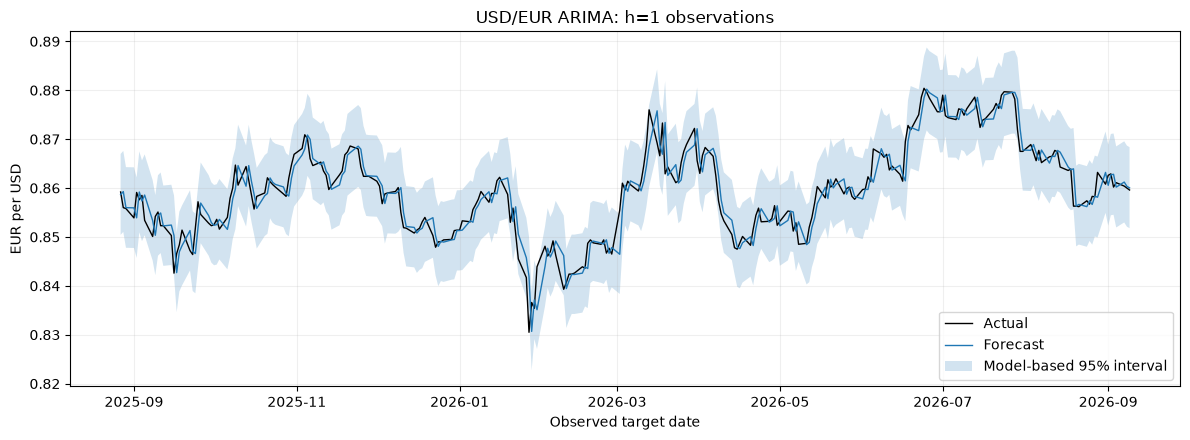

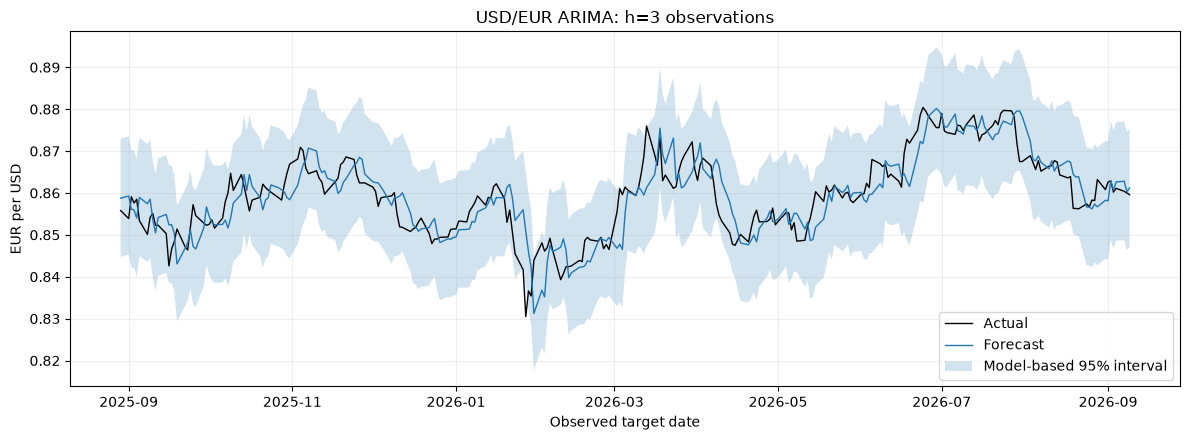

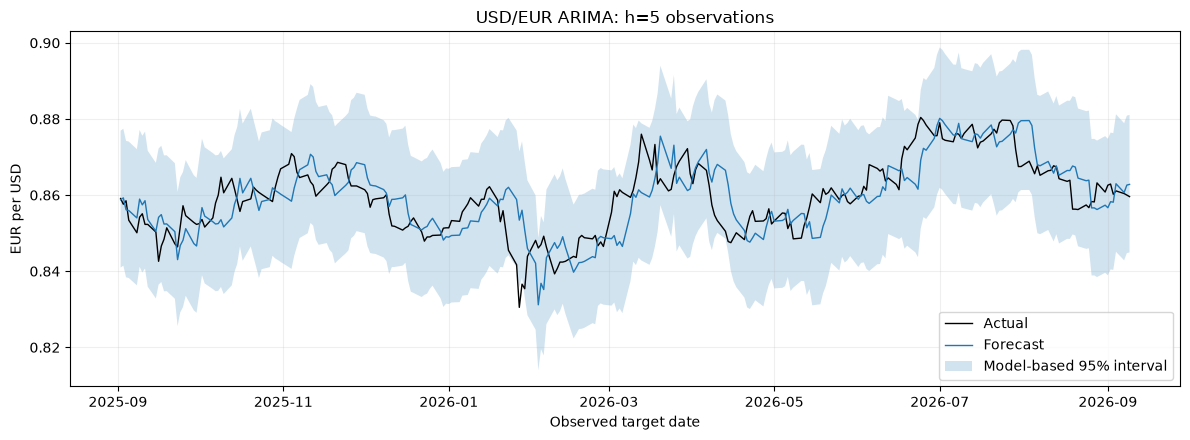

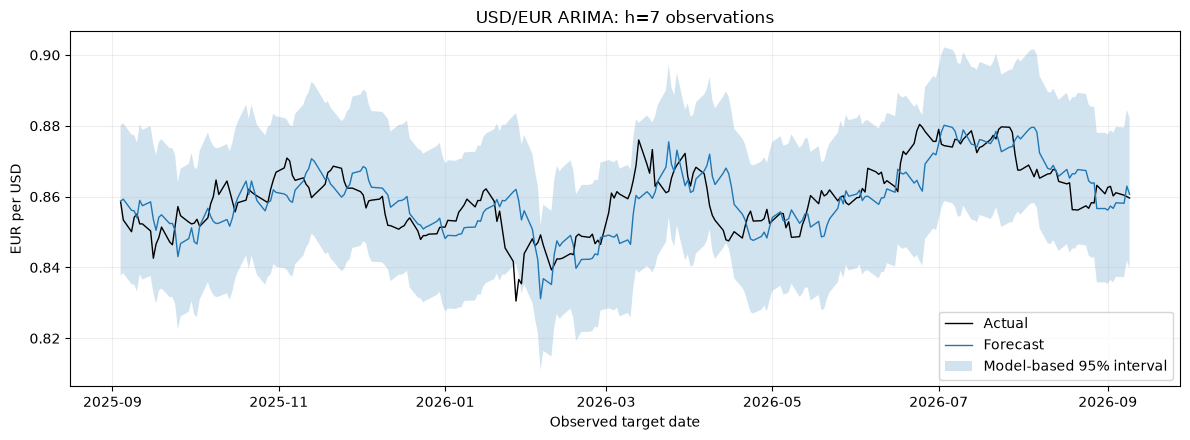

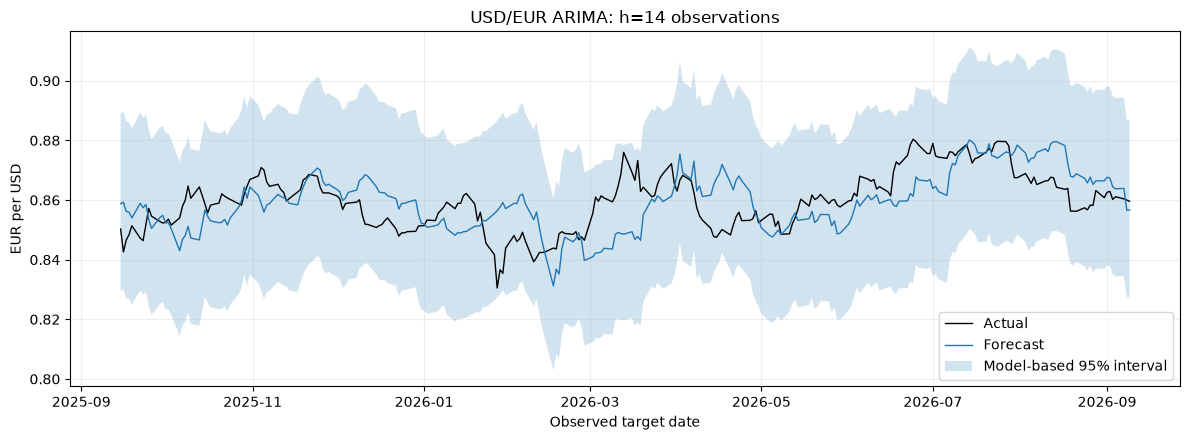

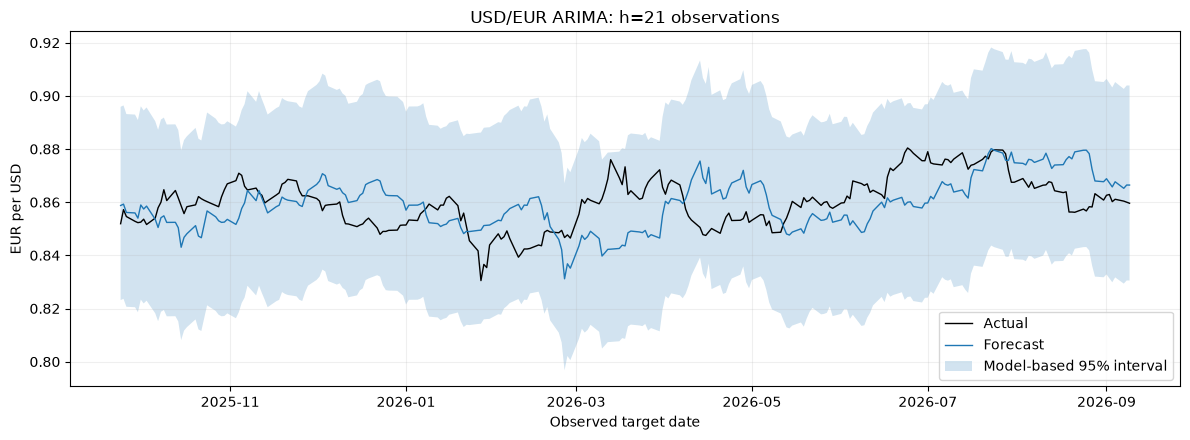

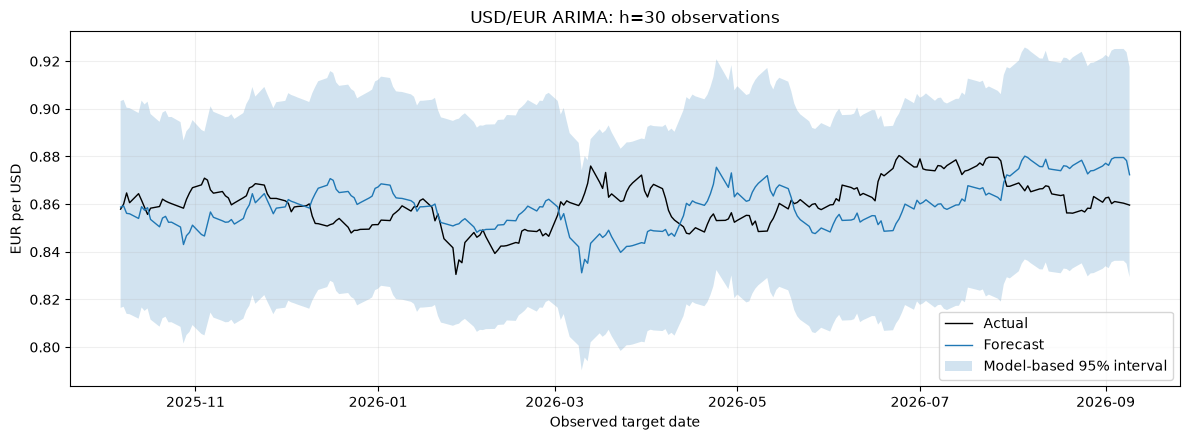

C:\Users\User\anaconda3\envs\vs_nine_tf\Lib\site-packages\statsmodels\stats\diagnostic.py:997: FutureWarning: acorr_lm currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an LMTestResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  return acorr_lm(


,sample,check,statistic,p_value,status,interpretation
0,Test cumulative log-return errors h=1; reporti...,Ljung-Box lag 10,18.553011,0.046321,REPORTED,Evidence of serial correlation; model_df=0; re...
1,Test cumulative log-return errors h=1; reporti...,Ljung-Box lag 20,28.167734,0.105488,REPORTED,No rejection of residual independence; model_d...
2,Test cumulative log-return errors h=1; reporti...,Ljung-Box lag 30,37.042690,0.175903,REPORTED,No rejection of residual independence; model_d...
3,Test cumulative log-return errors h=1; reporti...,Residual mean t-test,0.019035,0.984827,REPORTED,"Mean=3.979963e-06; descriptive, dependent erro..."
4,Test cumulative log-return errors h=1; reporti...,ARCH LM,27.350562,0.002291,REPORTED,Conditional variance evidence; no retuning
5,Test cumulative log-return errors h=1; reporti...,Jarque-Bera,26.499794,0.000002,REPORTED,Normality diagnostic; skew=-0.25195; kurtosis=...


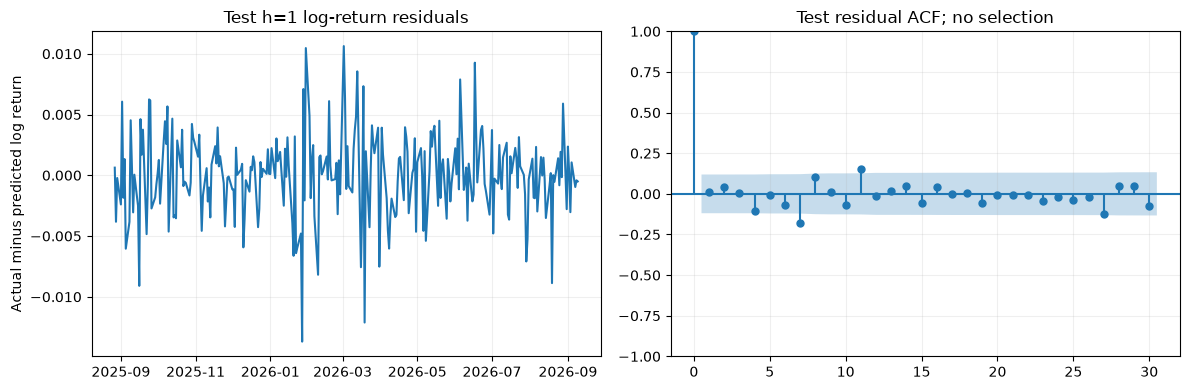

,sample,n,mean,SD,status
0,Train,1083,0.000016,0.004927,REPORTED
1,Test,271,0.000003,0.003437,REPORTED


In [14]:
for h in HORIZONS:
    g=forecasts.loc[forecasts.h.eq(h)].sort_values('target_date')
    fig,ax=plt.subplots()
    ax.plot(g.target_date,g.actual,label='Actual',color='black',linewidth=1)
    ax.plot(g.target_date,g.forecast,label='Forecast',linewidth=1)
    if 'lower95' in g: ax.fill_between(g.target_date,g.lower95,g.upper95,alpha=.2,label='Model-based 95% interval')
    ax.set(title=f'{ASSET_NAME} {MODEL}: h={h} observations',xlabel='Observed target date',ylabel=UNIT)
    ax.legend(); save_figure(fig,f'test_forecast_h{h}.png')
hdiag=HORIZONS[0]
g=forecasts.loc[forecasts.h.eq(hdiag)].sort_values('origin_date')
errors=np.log(g.actual/g.price_origin)-g.predicted_log_return
test_diagnostics=residual_report(errors,f'Test cumulative log-return errors h={hdiag}; reporting only')
save_table(test_diagnostics,'test_residual_diagnostics.csv'); display(test_diagnostics)
fig,axes=plt.subplots(1,2,figsize=(12,4))
axes[0].plot(g.target_date,errors); axes[0].set(title=f'Test h={hdiag} log-return residuals',ylabel='Actual minus predicted log return')
plot_acf(errors,lags=min(30,len(errors)//4),ax=axes[1]); axes[1].set_title('Test residual ACF; no selection')
save_figure(fig,'test_residual_diagnostics.png')
scale_comparison=pd.DataFrame([dict(sample='Train',n=n_train-1,mean=np.mean(returns[1:n_train]),SD=np.std(returns[1:n_train],ddof=1),status='REPORTED'),
    dict(sample='Test',n=n_test,mean=np.mean(returns[n_train:]),SD=np.std(returns[n_train:],ddof=1),status='REPORTED')])
save_table(scale_comparison,'return_scale_comparison.csv'); display(scale_comparison)

### 8.3 Fixed-origin forecast path from the final Train observation

One full 30-observation path from the final Train origin. Test actuals are plotted only for comparison; they do not update this fixed-origin path.

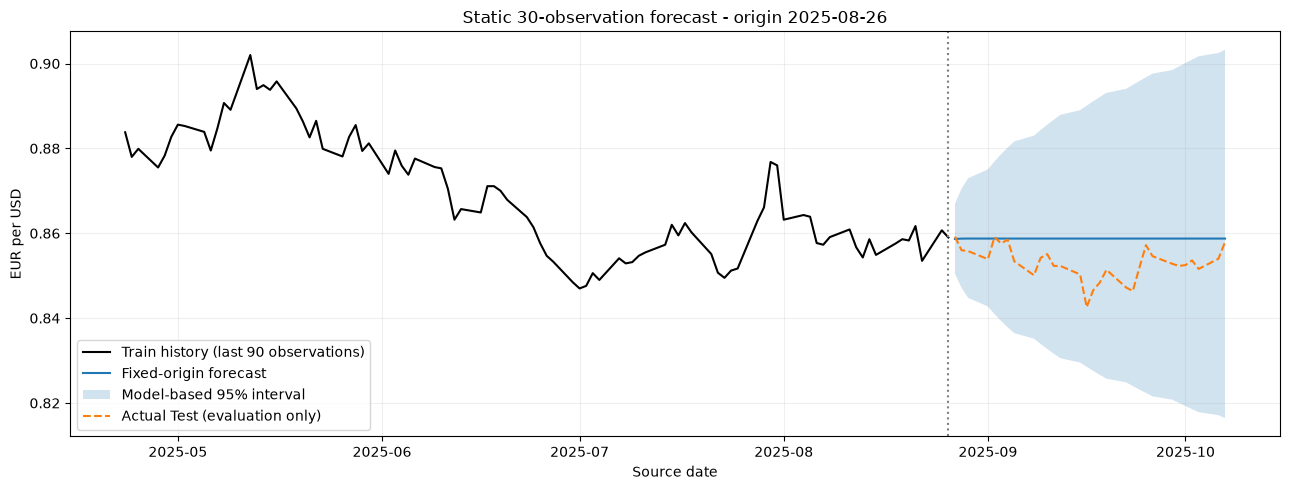

In [15]:
# One forecast path from the final Train origin, without observing later Test values.
static_fc = res.get_forecast(steps=MAX_H)
np.testing.assert_array_equal(np.asarray(res.params), frozen_params)
static_dates = df.index[n_train:n_train + MAX_H]
static_mean = np.exp(np.asarray(static_fc.predicted_mean))
static_ci = np.exp(np.asarray(static_fc.conf_int(alpha=ALPHA)))
static_forecasts = pd.DataFrame(dict(origin_date=df.index[T], h=np.arange(1, MAX_H+1),
    target_date=static_dates, actual=prices[n_train:n_train+MAX_H],
    forecast=static_mean, lower95=static_ci[:, 0], upper95=static_ci[:, 1]))
assert len(static_forecasts) == MAX_H and np.isfinite(static_forecasts.select_dtypes('number')).all().all()
save_table(static_forecasts, 'static_30d_forecast.csv')
fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(df.index[max(0, n_train-90):n_train], prices[max(0, n_train-90):n_train], color='black', label='Train history (last 90 observations)')
ax.plot(static_dates, static_mean, label='Fixed-origin forecast')
ax.fill_between(static_dates, static_ci[:, 0], static_ci[:, 1], alpha=.2, label='Model-based 95% interval')
ax.plot(static_dates, prices[n_train:n_train+MAX_H], linestyle='--', color='tab:orange', label='Actual Test (evaluation only)')
ax.axvline(df.index[T], color='gray', linestyle=':')
ax.set(title=f'Static {MAX_H}-observation forecast - origin {df.index[T].date()}', ylabel=UNIT, xlabel='Source date')
ax.legend(); save_figure(fig, '10_static_30d_fan.png')


### 8.4 RMSE and MAPE versus horizon (observations)

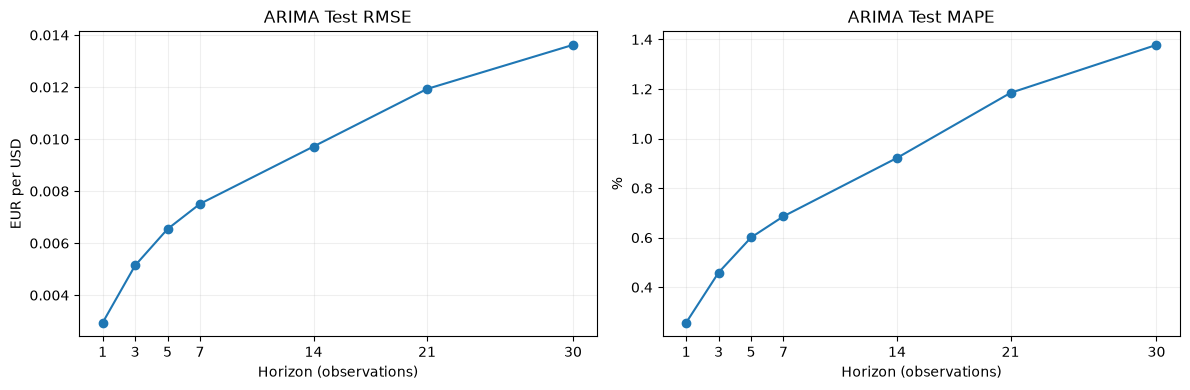

In [16]:
fig,axes=plt.subplots(1,2,figsize=(12,4))
for ax,metric,unit in zip(axes,['RMSE','MAPE'],[UNIT,'%']):
    ax.plot(evaluation.h,evaluation[metric],marker='o')
    ax.set(title=f'{MODEL} Test {metric}',xlabel='Horizon (observations)',ylabel=unit,xticks=HORIZONS)
save_figure(fig,'metrics_by_horizon.png')


## Step 9 - Summary from this execution

Summarize Train evidence, selected model, robust reporting, Test metrics, future values, limitations and output/parameter-freezing audits.

In [17]:
# Audit the complete Step 1-9 workflow before reporting successful completion.
required_tables = ['library_versions.csv', 'calendar_audit.csv', 'split_summary.csv', 'stationarity_tests.csv',
    'grid_search_aic_bic.csv', 'top3_candidates.csv', 'auto_arima_cross_check.csv', 'assumption_checks.csv',
    'parameter_significance.csv', 'model_roots.csv', 'candidate_diagnostics.csv', 'test_forecasts_all.csv',
    'future_forecasts.csv', 'metrics_by_horizon.csv', 'static_30d_forecast.csv',
    *[f'forecasts_h{h}.csv' for h in HORIZONS],
    *[f'future_forecast_daily_{days}d.csv' for days in DAILY_FORECAST_WINDOWS]]
assert all(name in notebook_tables and (TABLE_DIR/name).is_file() for name in required_tables)
assert model_fingerprint() == frozen_state
np.testing.assert_array_equal(np.asarray(res.params), frozen_params)
check('Complete Step 1-9 outputs', True, 'Includes robust reporting when required, fixed-origin plot and seven-horizon evaluation.')
process_audit = pd.DataFrame(process_rows)
display(process_audit)

lines = [f'# {ASSET_NAME} ARIMA - results from this execution', '',
    'Step order follows S&P_TEST/ARIMA_SnP.ipynb (Steps 1-9); input data, quote direction and calendar remain USD-specific.',
    f'Data: {n:,} observations; {df.index[0].date()} to {df.index[-1].date()}.', ASSET_NOTE,
    f'Raw chronological Train/Test: {n_train}/{n_test}; Train ends {df.index[T].date()}, Test starts {df.index[n_train].date()}.',
    'No validation, cross-validation, Test tuning or all-data refit.',
    f'Horizons: {HORIZONS} observations; RMSE units: {UNIT}.', CALENDAR_NOTE,
    '', '## Train-only stationarity evidence', markdown_table(stationarity_tests),
    '', f'## Selected model: {final_label}', f'AIC={res.aic:.6f}; BIC={res.bic:.6f}.',
    'Grid p,q=0..5 uses ARIMA.fit() defaults, matching the reference. The Top 3 converged finite-AIC fits are checked for Ljung-Box at lags 10/20/30 and roots. The lowest-AIC passing fit is selected; stop if none passes.',
    '', '## Train candidate comparison', markdown_table(candidate_diagnostics),
    '', '## Selected-model diagnostics', markdown_table(assumption_checks.loc[assumption_checks.model.eq(final_label)]),
    '', '## Robust covariance reporting',
    ('ARCH was significant: robust-covariance fits and parameter tables are reporting-only. Original fitted parameters remain frozen for all forecasts.'
     if robust_res is not None else 'No selected-model robust refit was required by the Train ARCH check.'),
    '', '## Historical Test metrics', markdown_table(evaluation),
    '', '## Future forecasts (no actuals or metrics)', markdown_table(future_forecasts),
    '', '## Limitations',
    '- Train fit and passing diagnostics do not establish forecast accuracy; no independent validation estimate exists.',
    '- This user-requested revision follows prior inspection of Test. Train-only selection does not make the existing Test period an untouched new holdout.',
    '- ARCH/non-normality can impair model-based interval coverage. Robust standard errors do not repair volatility or interval calibration.',
    '- Exponentiated log forecasts are conditional medians, not bias-corrected arithmetic means.',
    '- Horizon samples differ and longer-horizon errors overlap. MAPE is error percentage, not accuracy.',
    '- Missing source dates are disclosed, not filled. Future dates are weekday-pattern projections, not verified FX holiday sessions.',
    '- The univariate model does not observe news, policy changes, interest rates, inflation or unexpected events.',
    f'- Tables, figures, model artifacts and this summary are in OUTPUT/ARIMA_{ASSET}/; results are also embedded in this notebook.']
summary = '\n\n'.join(lines)
(SUMMARY_DIR / 'execution_summary.md').write_text(summary, encoding='utf-8')
display(Markdown(summary))
display(Markdown('### Full diagnostic table archive'))
for name in ['grid_search_aic_bic.csv', 'parameter_significance.csv', 'model_roots.csv',
             'candidate_diagnostics.csv', 'robust_parameter_significance.csv']:
    if name in notebook_tables:
        display(Markdown(f'**{name.removesuffix(".csv")}**'))
        show_table(notebook_tables[name])
write_json(SUMMARY_DIR / 'execution_audit.json', dict(completed=True, asset=ASSET, model=MODEL,
    step_reference='S&P_TEST/ARIMA_SnP.ipynb', n=n, n_train=n_train, n_test=n_test, horizons=HORIZONS,
    counts={int(h): int(c) for h,c in forecasts.groupby('h').size().items()},
    train_end=str(df.index[T].date()), test_start=str(df.index[n_train].date()), last_observation=str(df.index[-1].date()),
    parameters_frozen=model_fingerprint()==frozen_state, process_checks=process_rows,
    source_sha256=hashlib.sha256(DATA_PATH.read_bytes()).hexdigest(), python_executable=sys.executable,
    selected_model=final_label, robust_reporting=robust_res is not None,
    required_tables=required_tables, table_count=len(notebook_tables), figure_count=len(notebook_figures)))
print('Completed USD ARIMA: all Steps 1-9 executed; original Train parameters remained fixed.')


,check,statistic,p_value,status,interpretation
0,"Valid dates, finite strictly positive targets,...",NaN,NaN,PASS,Log representation was predetermined; stop rat...
1,Chronological raw 80/20 partition,NaN,NaN,PASS,"No shuffling, validation partition, or target ..."
2,Sufficient Train/Test history,NaN,NaN,PASS,Requested horizons and diagnostic lags must re...
3,Train stationarity supports differencing,1.0,NaN,PASS,Smallest d jointly supported by ADF and KPSS; ...
4,At least three converged finite-AIC Train cand...,NaN,NaN,PASS,Shortlist by AIC first; roots and Ljung-Box ar...
5,Train auto_arima cross-check completed,NaN,NaN,PASS,Supplementary evidence only; likelihood/trend ...
6,Top-3 Train candidate passes Ljung-Box and roots,NaN,NaN,PASS,Stop if none passes; no Test-based fallback or...
7,Fitted model and preprocessing remain frozen,NaN,NaN,PASS,Original Train ARIMA coefficients are unchange...
8,test: finite and valid log inversion,NaN,NaN,PASS,No clipping or post-Test parameter revision.
9,test: unique origin/horizon,NaN,NaN,PASS,


# USD/EUR ARIMA - results from this execution



Step order follows S&P_TEST/ARIMA_SnP.ipynb (Steps 1-9); input data, quote direction and calendar remain USD-specific.

Data: 1,355 observations; 2021-07-01 to 2026-09-09.

Quote direction follows USD/EUR in the supplied filename: EUR for one USD. The CSV does not specify fixing time or timezone.

Raw chronological Train/Test: 1084/271; Train ends 2025-08-26, Test starts 2025-08-27.

No validation, cross-validation, Test tuning or all-data refit.

Horizons: [1, 3, 5, 7, 14, 21, 30] observations; RMSE units: EUR per USD.

Observation-index modeling; source dates retained without filling gaps. Future dates use the declared weekday pattern only; holidays, omitted records and source-session conventions remain unknown.



## Train-only stationarity evidence

| d | test | statistic | p_value | status | interpretation | warnings |
| --- | --- | --- | --- | --- | --- | --- |
| 0 | ADF | -2.064543 | 0.259009 | FAIL | H0: unit root | FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning. / FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning a KPSSResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning. |
| 0 | KPSS | 0.586454 | 0.023868 | FAIL | H0: stationarity; p may be table bound | FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning. / FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning a KPSSResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning. |
| 1 | ADF | -24.338016 | 0.000000 | PASS | H0: unit root | FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning. / InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned. / FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning a KPSSResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning. |
| 1 | KPSS | 0.310112 | 0.100000 | PASS | H0: stationarity; p may be table bound | FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning. / InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned. / FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning a KPSSResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning. |



## Selected model: ARIMA(2,1,0), trend=n

AIC=-8431.940115; BIC=-8416.977645.

Grid p,q=0..5 uses ARIMA.fit() defaults, matching the reference. The Top 3 converged finite-AIC fits are checked for Ljung-Box at lags 10/20/30 and roots. The lowest-AIC passing fit is selected; stop if none passes.



## Train candidate comparison

| model | AIC | ljung_box_pass | roots_pass | arch_pvalue |
| --- | --- | --- | --- | --- |
| ARIMA(2,1,0), trend=n | -8431.940115 | True | True | 0.000000 |
| ARIMA(0,1,2), trend=n | -8431.880629 | True | True | 0.000000 |
| ARIMA(1,1,0), trend=n | -8431.527391 | True | True | 0.000000 |



## Selected-model diagnostics

| model | test | statistic | p_value | pass_fail | note |
| --- | --- | --- | --- | --- | --- |
| ARIMA(2,1,0), trend=n | Ljung-Box lag 10 | 7.246233 | 0.510314 | PASS | model_df=2 |
| ARIMA(2,1,0), trend=n | Ljung-Box lag 20 | 16.859867 | 0.532759 | PASS | model_df=2 |
| ARIMA(2,1,0), trend=n | Ljung-Box lag 30 | 37.137852 | 0.115851 | PASS | model_df=2 |
| ARIMA(2,1,0), trend=n | Mean = 0 (t-test) | 0.112871 | 0.910154 | PASS | Residual mean=1.68801e-05 |
| ARIMA(2,1,0), trend=n | ARCH LM (10 lags) | 64.315324 | 0.000000 | FAIL |  |
| ARIMA(2,1,0), trend=n | Jarque-Bera | 124.890548 | 0.000000 | FAIL | skew=-0.2611, kurtosis=4.5795 |
| ARIMA(2,1,0), trend=n | AR roots outside unit circle | 4.598373 | nan | PASS | All /root/>1: True |
| ARIMA(2,1,0), trend=n | MA roots outside unit circle | nan | nan | REPORTED | N/A: no roots |
| ARIMA(2,1,0), trend=n | Parameter significance: ar.L1 | -0.000571 | 0.981740 | FAIL | Report only; estimate in statistic column, significance uses p < alpha |
| ARIMA(2,1,0), trend=n | Parameter significance: ar.L2 | -0.047292 | 0.084727 | FAIL | Report only; estimate in statistic column, significance uses p < alpha |
| ARIMA(2,1,0), trend=n | Parameter significance: sigma2 | 0.000024 | 0.000000 | PASS | Report only; estimate in statistic column, significance uses p < alpha |



## Robust covariance reporting

ARCH was significant: robust-covariance fits and parameter tables are reporting-only. Original fitted parameters remain frozen for all forecasts.



## Historical Test metrics

| h | n | first_target_date | last_target_date | RMSE | MAPE | zero_actuals | RMSE_unit | MAPE_unit |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 1 | 271 | 2025-08-27 00:00:00 | 2026-09-09 00:00:00 | 0.002946 | 0.257182 | 0 | EUR per USD | % |
| 3 | 269 | 2025-08-29 00:00:00 | 2026-09-09 00:00:00 | 0.005142 | 0.459360 | 0 | EUR per USD | % |
| 5 | 267 | 2025-09-02 00:00:00 | 2026-09-09 00:00:00 | 0.006543 | 0.600657 | 0 | EUR per USD | % |
| 7 | 265 | 2025-09-04 00:00:00 | 2026-09-09 00:00:00 | 0.007510 | 0.686178 | 0 | EUR per USD | % |
| 14 | 258 | 2025-09-15 00:00:00 | 2026-09-09 00:00:00 | 0.009715 | 0.921764 | 0 | EUR per USD | % |
| 21 | 251 | 2025-09-24 00:00:00 | 2026-09-09 00:00:00 | 0.011927 | 1.184256 | 0 | EUR per USD | % |
| 30 | 242 | 2025-10-07 00:00:00 | 2026-09-09 00:00:00 | 0.013621 | 1.377936 | 0 | EUR per USD | % |



## Future forecasts (no actuals or metrics)

| h | origin_date | target_date | target_date_status | price_origin | forecast | lower95 | upper95 |
| --- | --- | --- | --- | --- | --- | --- | --- |
| 1 | 2026-09-09 00:00:00 | 2026-09-10 00:00:00 | PROJECTED: weekday pattern, holidays/omissions unknown | 0.859600 | 0.859619 | 0.851376 | 0.867942 |
| 3 | 2026-09-09 00:00:00 | 2026-09-14 00:00:00 | PROJECTED: weekday pattern, holidays/omissions unknown | 0.859600 | 0.859637 | 0.845634 | 0.873872 |
| 5 | 2026-09-09 00:00:00 | 2026-09-16 00:00:00 | PROJECTED: weekday pattern, holidays/omissions unknown | 0.859600 | 0.859636 | 0.841823 | 0.877827 |
| 7 | 2026-09-09 00:00:00 | 2026-09-18 00:00:00 | PROJECTED: weekday pattern, holidays/omissions unknown | 0.859600 | 0.859636 | 0.838706 | 0.881089 |
| 14 | 2026-09-09 00:00:00 | 2026-09-29 00:00:00 | PROJECTED: weekday pattern, holidays/omissions unknown | 0.859600 | 0.859636 | 0.830374 | 0.889929 |
| 21 | 2026-09-09 00:00:00 | 2026-10-08 00:00:00 | PROJECTED: weekday pattern, holidays/omissions unknown | 0.859600 | 0.859636 | 0.824013 | 0.896800 |
| 30 | 2026-09-09 00:00:00 | 2026-10-21 00:00:00 | PROJECTED: weekday pattern, holidays/omissions unknown | 0.859600 | 0.859636 | 0.817287 | 0.904180 |



## Limitations

- Train fit and passing diagnostics do not establish forecast accuracy; no independent validation estimate exists.

- This user-requested revision follows prior inspection of Test. Train-only selection does not make the existing Test period an untouched new holdout.

- ARCH/non-normality can impair model-based interval coverage. Robust standard errors do not repair volatility or interval calibration.

- Exponentiated log forecasts are conditional medians, not bias-corrected arithmetic means.

- Horizon samples differ and longer-horizon errors overlap. MAPE is error percentage, not accuracy.

- Missing source dates are disclosed, not filled. Future dates are weekday-pattern projections, not verified FX holiday sessions.

- The univariate model does not observe news, policy changes, interest rates, inflation or unexpected events.

- Tables, figures, model artifacts and this summary are in OUTPUT/ARIMA_USD/; results are also embedded in this notebook.

### Full diagnostic table archive

**grid_search_aic_bic**

model,p,d,q,trend,AIC,BIC,converged,roots_valid,warnings,error
"ARIMA(0,1,0), trend=n",0,1,0,n,"-8,433.526573","-8,428.539083",False,True,ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals,
"ARIMA(2,1,0), trend=n",2,1,0,n,"-8,431.940115","-8,416.977645",True,True,,
"ARIMA(0,1,2), trend=n",0,1,2,n,"-8,431.880629","-8,416.918158",True,True,,
"ARIMA(0,1,0), trend=t",0,1,0,t,"-8,431.536367","-8,421.561386",False,True,ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals,
"ARIMA(1,1,0), trend=n",1,1,0,n,"-8,431.527391","-8,421.552411",True,True,,
"ARIMA(0,1,1), trend=n",0,1,1,n,"-8,431.526231","-8,421.551250",True,True,,
"ARIMA(3,1,0), trend=n",3,1,0,n,"-8,430.023159","-8,410.073198",True,True,,
"ARIMA(2,1,1), trend=n",2,1,1,n,"-8,429.981585","-8,410.031624",False,True,ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals,
"ARIMA(0,1,3), trend=n",0,1,3,n,"-8,429.961147","-8,410.011186",True,True,,
"ARIMA(2,1,0), trend=t",2,1,0,t,"-8,429.952641","-8,410.002680",False,True,ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals,


...

**candidate_diagnostics**

model,AIC,ljung_box_pass,roots_pass,arch_pvalue
"ARIMA(2,1,0), trend=n","-8,431.940115",True,True,0.000000
"ARIMA(0,1,2), trend=n","-8,431.880629",True,True,0.000000
"ARIMA(1,1,0), trend=n","-8,431.527391",True,True,0.000000


**robust_parameter_significance**

model,parameter,estimate,robust_standard_error,robust_p_value,converged,warnings
"ARIMA(2,1,0), trend=n",ar.L1,-0.000571,0.036936,0.987667,True,
"ARIMA(2,1,0), trend=n",ar.L2,-0.047292,0.033681,0.160277,True,
"ARIMA(2,1,0), trend=n",sigma2,0.000024,0.000001,0.000000,True,
"ARIMA(0,1,2), trend=n",ma.L1,-0.001144,0.037020,0.975340,True,
"ARIMA(0,1,2), trend=n",ma.L2,-0.045407,0.034079,0.182732,True,
"ARIMA(0,1,2), trend=n",sigma2,0.000024,0.000001,0.000000,True,
"ARIMA(1,1,0), trend=n",ar.L1,-0.000585,0.037090,0.987417,True,
"ARIMA(1,1,0), trend=n",sigma2,0.000024,0.000001,0.000000,True,


Completed USD ARIMA: all Steps 1-9 executed; original Train parameters remained fixed.


## Method references

- [statsmodels ARIMA](https://www.statsmodels.org/stable/generated/statsmodels.tsa.arima.model.ARIMA.html)
- [ARIMAResults.apply with fixed parameters](https://www.statsmodels.org/stable/generated/statsmodels.tsa.arima.model.ARIMAResults.apply.html)
- [pmdarima auto_arima](https://alkaline-ml.com/pmdarima/modules/generated/pmdarima.arima.auto_arima.html)
- [NYSE holidays and trading hours](https://www.nyse.com/trade/hours-calendars)
- [NYSE special closure, 9 January 2025](https://www.nyse.com/publicdocs/nyse/markets/american-options/rule-interpretations/2025/National_Day_of_Mourning_20250102.pdf)

Step-order reference: `../S&P_TEST/ARIMA_SnP.ipynb`. Data, quote units, observed-step calendar and output paths remain USD-specific.